# Parte Comum: K-Means no dataset Obesity

**Dataset:** *Estimation of obesity levels based on eating habits and physical condition* (Palechor & De la Hoz Manotas, 2019), UCI Machine Learning Repository, id 544. São 2.111 registros e 17 atributos, de pessoas do México, do Peru e da Colômbia.

**Roteiro**
1. EDA dos 4 pilares: estrutura, distribuições, relações e outliers.
2. Pré-processamento e padronização.
3. K-Means, passada 1: k de 2 a 10, escolhido pelo Método do Cotovelo.
4. K-Means, passada 2: k = 7, o número real de classes.
5. Em cada passada: mapear cluster → classe majoritária, montar a matriz de confusão e calcular acurácia, precisão e recall por classe.
6. Comparação das passadas e discussão crítica sobre as classes.

> O código deste notebook foi gerado com apoio de IA (Claude) e está marcado com `# [IA] Claude`. O grupo revisou o código e os resultados. Ver `docs/DECLARACAO_IA.pdf`.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from scipy.stats import entropy
from scipy.stats import entropy
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, silhouette_score)

SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Funciona tanto a partir de notebooks/parte_comum/ quanto da raiz do repositório
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "parte_comum").exists()), Path.cwd())
CSV = RAIZ / "data" / "parte_comum" / "ObesityDataSet_raw_and_data_sinthetic.csv"
OUT = RAIZ / "out" / "parte_comum"
FIG = OUT / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

if CSV.exists():
    df_raw = pd.read_csv(CSV)
else:  # Colab sem o repositório: baixa direto da UCI
    import io, urllib.request, zipfile
    url = ("https://archive.ics.uci.edu/static/public/544/estimation+of+obesity+levels"
           "+based+on+eating+habits+and+physical+condition.zip")
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        df_raw = pd.read_csv(z.open("ObesityDataSet_raw_and_data_sinthetic.csv"))

ALVO = "NObeyesdad"
ORDEM_CLASSES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
                 "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
print(df_raw.shape)
df_raw.head()

(2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1. EDA, pilar 1: estrutura

O dicionário abaixo traduz as siglas do dataset.

| Atributo | Significado | Tipo |
|---|---|---|
| Gender, Age, Height (m), Weight (kg) | sexo, idade, altura e peso | demográfico e físico |
| family_history_with_overweight | histórico familiar de sobrepeso | binário |
| FAVC | consome alimentos muito calóricos com frequência | binário |
| FCVC | frequência de consumo de vegetais (1 a 3) | ordinal |
| NCP | número de refeições principais por dia (1 a 4) | ordinal |
| CAEC | come entre as refeições (no, Sometimes, Frequently, Always) | ordinal |
| SMOKE | fuma | binário |
| CH2O | consumo diário de água (1 a 3) | ordinal |
| SCC | monitora as calorias | binário |
| FAF | frequência de atividade física (0 a 3) | ordinal |
| TUE | tempo diário em dispositivos eletrônicos (0 a 2) | ordinal |
| CALC | consumo de álcool (no, Sometimes, Frequently, Always) | ordinal |
| MTRANS | meio de transporte | nominal |
| **NObeyesdad** | **nível de obesidade, o rótulo de classe (7 classes)** | alvo |

In [2]:
# [IA] Claude: tipos, ausentes, duplicatas e cardinalidade
estrutura = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_ausentes": df_raw.isna().sum(),
    "n_unicos": df_raw.nunique(),
    "exemplo": df_raw.iloc[0],
})
estrutura.to_csv(OUT / "estrutura.csv")
print("Linhas duplicadas:", df_raw.duplicated().sum())
print("Valores ausentes no total:", df_raw.isna().sum().sum())
estrutura

Linhas duplicadas: 24
Valores ausentes no total: 0


,dtype,n_ausentes,n_unicos,exemplo
Gender,object,0,2,Female
Age,float64,0,1402,21.0
Height,float64,0,1574,1.62
Weight,float64,0,1525,64.0
family_history_with_overweight,object,0,2,yes
FAVC,object,0,2,no
FCVC,float64,0,810,2.0
NCP,float64,0,635,3.0
CAEC,object,0,4,Sometimes
SMOKE,object,0,2,no


In [3]:
# [IA] Claude: atributos ordinais que deveriam ser inteiros, mas têm casas decimais
ordinais_num = ["FCVC", "NCP", "CH2O", "FAF", "TUE"]
frac_nao_inteiro = {c: (df_raw[c] % 1 != 0).mean() for c in ordinais_num + ["Age"]}
pd.Series(frac_nao_inteiro, name="% de valores não inteiros").mul(100).round(1)

FCVC    39.1
NCP     30.3
CH2O    61.1
FAF     57.2
TUE     54.6
Age     65.1
Name: % de valores não inteiros, dtype: float64

**O que a estrutura mostra**
- 2.111 linhas e 17 colunas: 8 numéricas e 9 categóricas. **Não há valores ausentes.**
- Há **24 linhas duplicadas**. Elas são removidas, porque contam duas vezes no cálculo dos centróides.
- Os autores informam que **77% dos registros são sintéticos**. Só 23% vieram do questionário online. Isso explica dois fatos:
  - as respostas ordinais (FCVC, NCP, CH2O, FAF e TUE) e a idade aparecem com casas decimais, como em FCVC = 2,39, que não é uma resposta possível;


## 1. EDA, pilar 1.1: Tratamento


In [4]:
AB = "#2563EB"
PN = "#F59E0B"
AP = "#10B981"
O  = "#E11D48"
COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

df = df_raw.copy().drop_duplicates().reset_index(drop=True)
df["IMC"] = df["Weight"] / df["Height"] ** 2
df_K = df.copy().drop_duplicates().reset_index(drop=True)
print(df.shape)
df_clean = df.drop_duplicates().reset_index(drop=True)



df_clean = df.set_axis(['Sexo', 'Idade', 'Altura', 'Peso', 'Historico familiar de obesidade',
       'Come altas calorias regularmente', 'Consumo de vegetais', 'Refeições por dia', 'Consumo de Lanches entre refeições', 'Fumante', 'Consumo de água diário', 'Você monitora suas calorias', 'Frequencia atividade física', 'Tempo de tela médio',
       'Consumo de álcool', 'MTRANS', 'Nível Obesidade', 'IMC'], axis=1)


df_clean['Sexo'] = df_clean['Sexo'].replace({'Female': 'Feminino', 'Male': 'Masculino'})
df_clean['Historico familiar de obesidade'] = df_clean['Historico familiar de obesidade'].replace({'yes': 'Sim', 'no': 'Não'})
df_clean['Come altas calorias regularmente'] = df_clean['Come altas calorias regularmente'].replace({'yes': 'Sim', 'no': 'Não'})

#print(df["CAEC"].unique())
#'Sometimes' 'Frequently' 'Always' 'no'
df_clean['Consumo de Lanches entre refeições'] = df_clean['Consumo de Lanches entre refeições'].replace({'Sometimes': 'As vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre', 'no': 'Não'})
#print(df_clean["CAEC"].unique())

df_clean['Fumante'] = df_clean['Fumante'].replace({'yes': 'Sim', 'no': 'Não'})
df_clean['Você monitora suas calorias'] = df_clean['Você monitora suas calorias'].replace({'yes': 'Sim', 'no': 'Não'})

#print(df["CALC"].unique())
##'Sometimes' 'Frequently' 'Always' 'no'
df_clean['Consumo de álcool'] = df_clean['Consumo de álcool'].replace({'Sometimes': 'As vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre', 'no': 'Não'})
#print(df_clean["CALC"].unique())


df_clean_K = df_clean.copy() # --> Posteriormente usado no KNN para ter as 7 classes
df_clean['Nível Obesidade'] = df_clean['Nível Obesidade'].replace({'Normal_Weight': 'Peso Normal', 'Overweight_Level_I': 'Acima do peso',
                                                                   'Overweight_Level_II': 'Acima do peso', 'Obesity_Type_I': 'Obeso',
                                                                   'Obesity_Type_II': 'Obeso', 'Obesity_Type_III': 'Obeso',
                                                                   'Insufficient_Weight': 'Abaixo do Peso'})

# Tentar categorizar cada categoria em 3 grupos: Peso Normal, Abaixo do


print(df_clean["Nível Obesidade"].unique())


#print(df["MTRANS"].unique())
##'Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike'
df_clean['MTRANS'] = df_clean['MTRANS'].replace({'Public_Transportation': 'Trasnporte Público', 'Walking': 'Andando', 'Automobiles': 'Automóvel', 'Motorbike': 'Mótocicleta', 'Bike': 'Bicicleta'})
#print(df_clean["MTRANS"].unique())

df = df_clean
print(df.shape)

(2087, 18)
['Peso Normal' 'Acima do peso' 'Obeso' 'Abaixo do Peso']
(2087, 18)


## 2. EDA, pilar 2: distribuições

In [5]:
VARS_QUANT = ['Idade', 'Altura', 'Peso', 'Consumo de vegetais', 'Refeições por dia', 'Consumo de água diário', 'Frequencia atividade física', 'Tempo de tela médio', 'IMC']
VARS_QUALI = ['Sexo', 'Historico familiar de obesidade', 'Come altas calorias regularmente', 'Consumo de Lanches entre refeições', 'Fumante', 'Você monitora suas calorias', 'Consumo de álcool', 'MTRANS', 'Nível Obesidade']

print("Estatísticas descritivas — Dataset completo")

desc = df[VARS_QUANT].describe().T

desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

display(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(
        cmap="magma",
        subset=["skewness", "kurtosis"]
    )
)

Estatísticas descritivas — Dataset completo


,mean,median,std,min,max,skewness,kurtosis
Idade,24.35,22.85,6.37,14.00,61.00,1.51,2.77
Altura,1.70,1.70,0.09,1.45,1.98,-0.02,-0.56
Peso,86.86,83.10,26.19,39.00,173.00,0.24,-0.71
Consumo de vegetais,2.42,2.40,0.53,1.00,3.00,-0.45,-0.62
Refeições por dia,2.70,3.00,0.76,1.00,4.00,-1.14,0.53
Consumo de água diário,2.00,2.00,0.61,1.00,3.00,-0.11,-0.86
Frequencia atividade física,1.01,1.00,0.85,0.00,3.00,0.49,-0.64
Tempo de tela médio,0.66,0.63,0.61,0.00,2.00,0.61,-0.55
IMC,29.77,28.90,8.02,13.00,50.81,0.14,-0.82


In [6]:
COL_CATEGORIA = "Nível Obesidade"


for categoria, grupo in df.groupby("Nível Obesidade"):

    print(categoria)

    desc = grupo[VARS_QUANT].describe().T
    desc["skewness"] = grupo[VARS_QUANT].skew()
    desc["kurtosis"] = grupo[VARS_QUANT].kurtosis()

    display(
        desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
        .rename(columns={"50%": "median"})
        .round(2)
        .style.format(precision=2)
        .background_gradient(
            cmap="magma",
            subset=["skewness", "kurtosis"]
        )
    )


Abaixo do Peso


,mean,median,std,min,max,skewness,kurtosis
Idade,19.77,19.21,2.69,16.00,39.00,2.78,14.29
Altura,1.69,1.70,0.10,1.52,1.90,-0.10,-0.88
Peso,50.01,50.00,5.99,39.00,65.00,0.18,-0.72
Consumo de vegetais,2.47,2.70,0.59,1.00,3.00,-1.00,0.02
Refeições por dia,2.94,3.00,0.88,1.00,4.00,-1.04,0.25
Consumo de água diário,1.88,2.00,0.60,1.00,3.00,0.11,-0.87
Frequencia atividade física,1.27,1.37,0.85,0.00,3.00,-0.17,-1.25
Tempo de tela médio,0.85,1.00,0.64,0.00,2.00,0.19,-1.00
IMC,17.39,17.53,0.79,13.00,19.08,-1.92,7.01


Acima do peso


,mean,median,std,min,max,skewness,kurtosis
Idade,25.31,22.75,7.43,16.00,56.00,1.40,2.03
Altura,1.70,1.70,0.09,1.45,1.93,-0.22,-0.32
Peso,78.38,79.64,9.34,53.00,102.00,-0.13,-0.30
Consumo de vegetais,2.27,2.00,0.47,1.00,3.00,0.08,-0.34
Refeições por dia,2.54,3.00,0.84,1.00,4.00,-0.73,-0.60
Consumo de água diário,2.02,2.00,0.57,1.00,3.00,-0.02,-0.58
Frequencia atividade física,1.01,0.99,0.85,0.00,3.00,0.66,-0.38
Tempo de tela médio,0.67,0.62,0.63,0.00,2.00,0.58,-0.75
IMC,27.11,27.00,1.36,22.83,30.36,0.16,-0.87


Obeso


,mean,median,std,min,max,skewness,kurtosis
Idade,25.81,25.14,5.92,15.00,52.00,1.15,1.11
Altura,1.72,1.72,0.09,1.50,1.98,0.07,-0.62
Peso,109.08,109.98,17.36,75.00,173.00,0.18,-0.00
Consumo de vegetais,2.52,2.72,0.51,1.00,3.00,-0.65,-0.61
Refeições por dia,2.72,3.00,0.62,1.00,4.00,-1.84,2.18
Consumo de água diário,2.07,2.08,0.61,1.00,3.00,-0.27,-1.00
Frequencia atividade física,0.87,0.90,0.77,0.00,3.00,0.52,-0.55
Tempo de tela médio,0.60,0.55,0.55,0.00,2.00,0.76,-0.09
IMC,36.96,36.34,4.54,29.91,50.81,0.47,-0.69


Peso Normal


,mean,median,std,min,max,skewness,kurtosis
Idade,21.76,21.00,5.12,14.00,61.00,3.15,16.25
Altura,1.68,1.66,0.10,1.50,1.93,0.36,-0.53
Peso,62.16,61.00,9.32,42.30,87.00,0.30,-0.38
Consumo de vegetais,2.34,2.00,0.59,1.00,3.00,-0.27,-0.65
Refeições por dia,2.75,3.00,0.87,1.00,4.00,-1.14,0.44
Consumo de água diário,1.86,2.00,0.64,1.00,3.00,0.13,-0.58
Frequencia atividade física,1.25,1.00,1.02,0.00,3.00,0.31,-1.03
Tempo de tela médio,0.68,1.00,0.69,0.00,2.00,0.52,-0.81
IMC,22.01,22.12,1.85,18.49,24.91,-0.21,-1.09


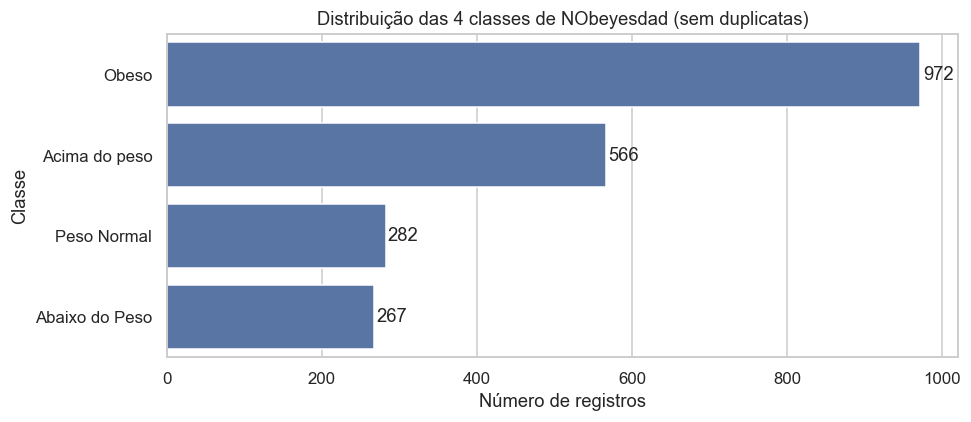

In [7]:
# [IA] Claude: distribuição da classe
fig, ax = plt.subplots(figsize=(9, 4))
cont = df["Nível Obesidade"].value_counts()
sns.barplot(x=cont.values, y=cont.index, ax=ax, color="#4C72B0")
for i, v in enumerate(cont.values):
    ax.text(v + 3, i, str(v), va="center")
ax.set(title="Distribuição das 4 classes de NObeyesdad (sem duplicatas)",
       xlabel="Número de registros", ylabel="Classe")
plt.tight_layout(); plt.savefig(FIG / "C1_classes.png"); plt.show()

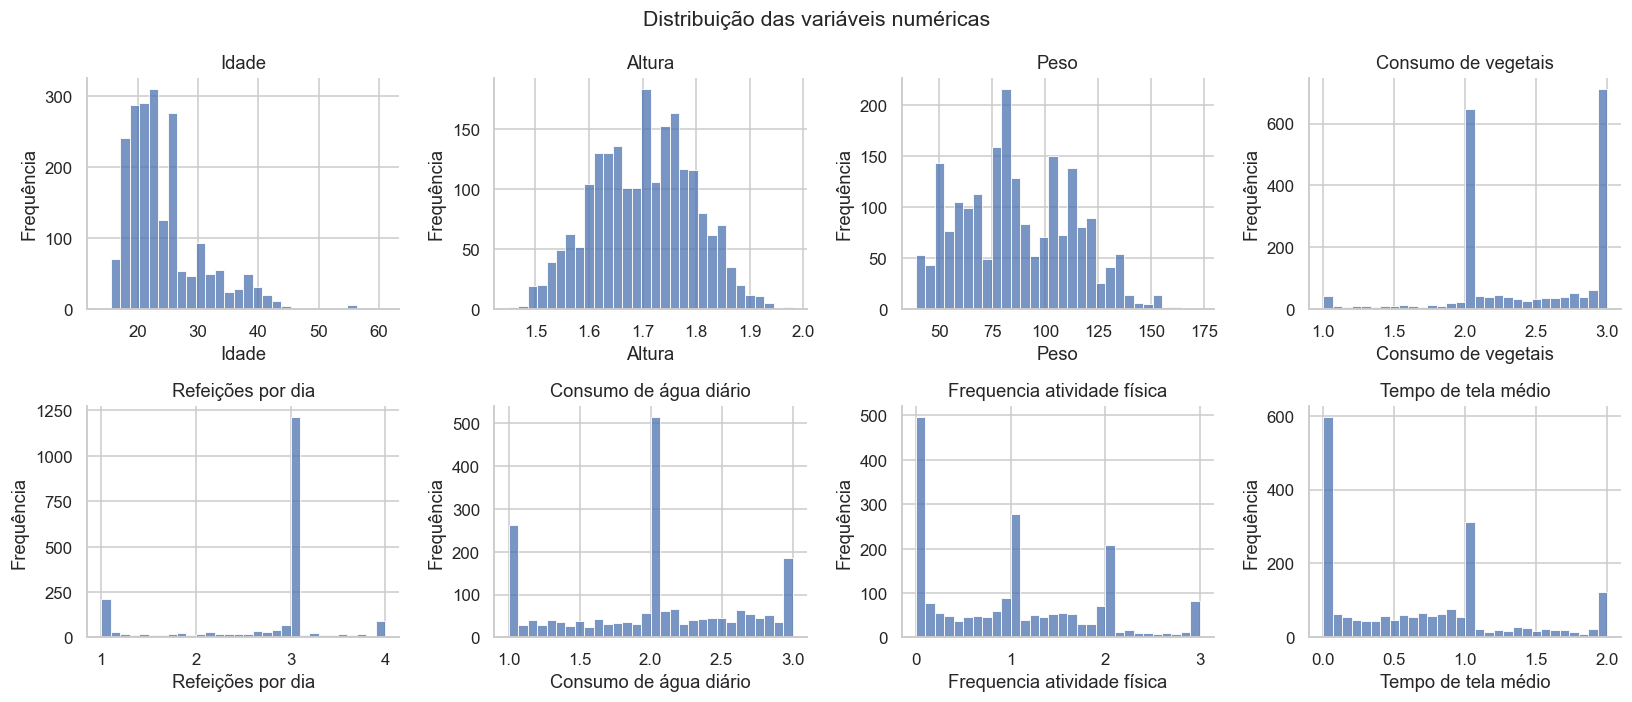

In [8]:
# [IA] Claude: histogramas das variáveis numéricas

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, VARS_QUANT):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    sns.histplot(df[c], bins=30, ax=ax, color="#4C72B0")
    ax.set(title=c, xlabel=c, ylabel="Frequência")
fig.suptitle("Distribuição das variáveis numéricas", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C2_histogramas.png"); plt.show()



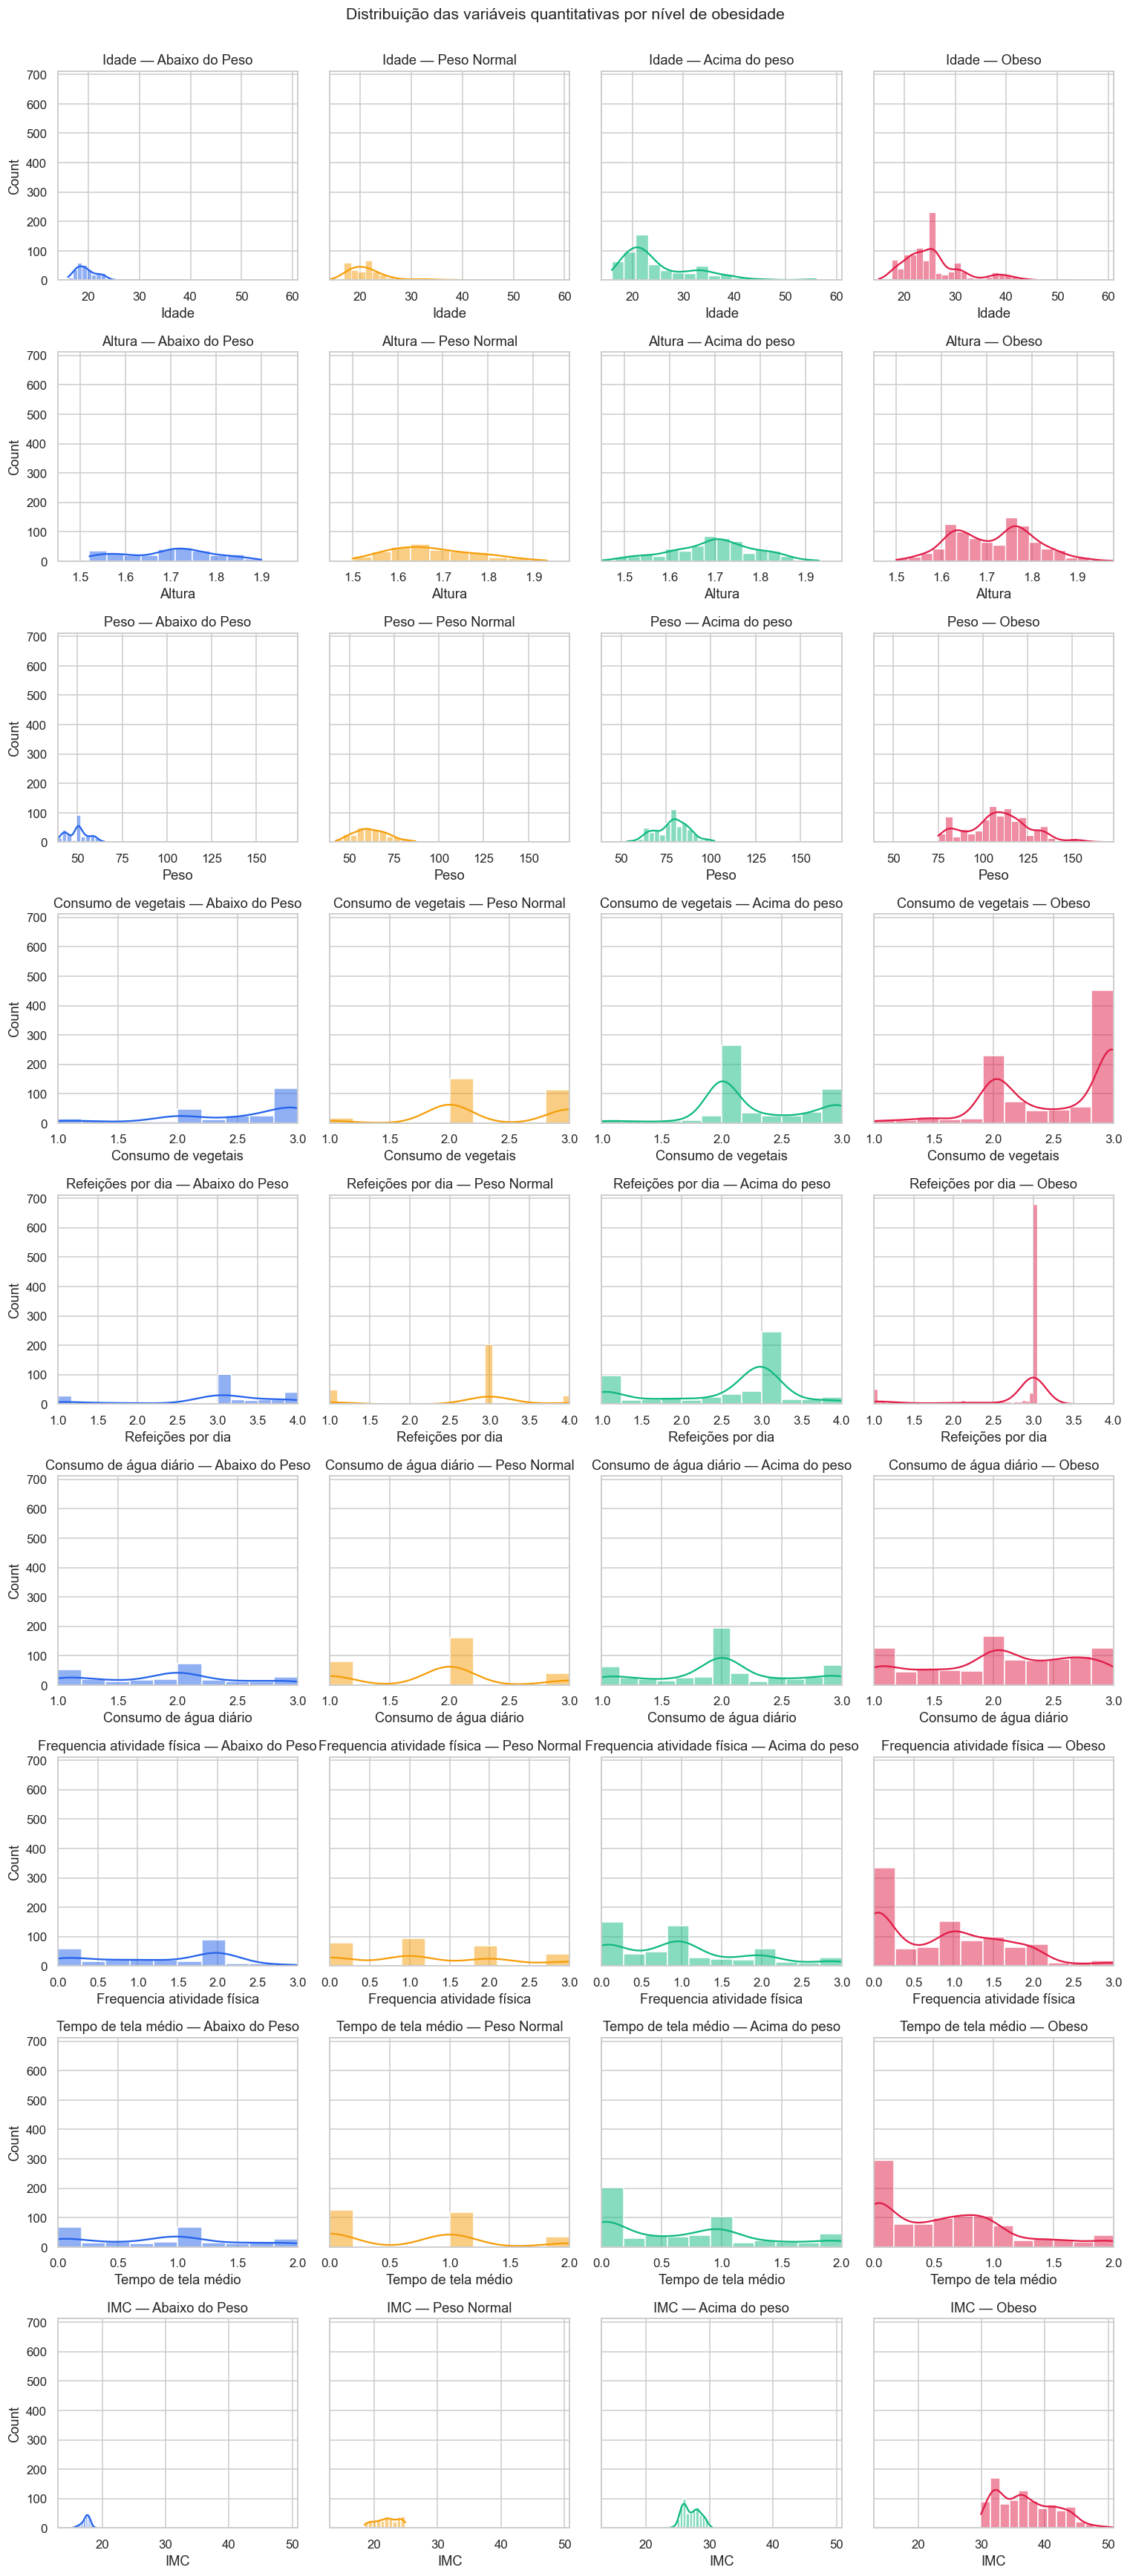

In [9]:
fig, axes = plt.subplots(len(VARS_QUANT), 4, figsize=(14, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Abaixo do Peso", AB) ,("Peso Normal", PN), ("Acima do peso", AP), ("Obeso", O)]):
        subset = df[df["Nível Obesidade"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das variáveis quantitativas por nível de obesidade", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

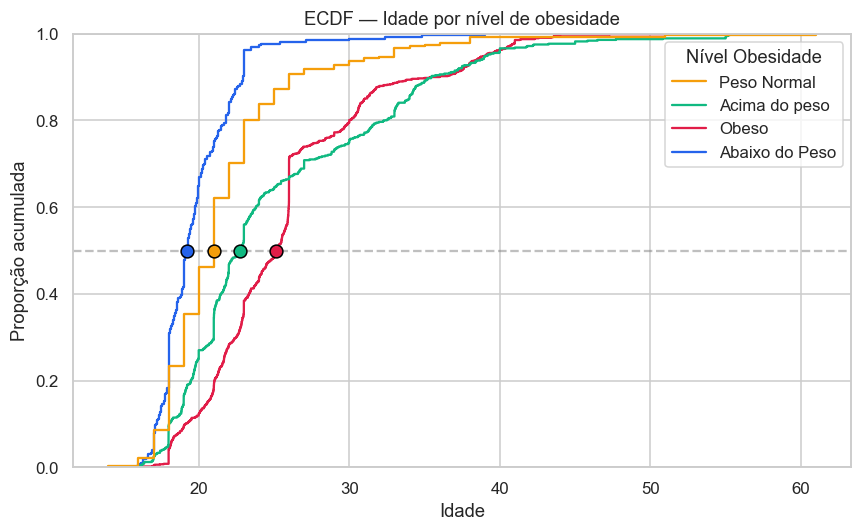

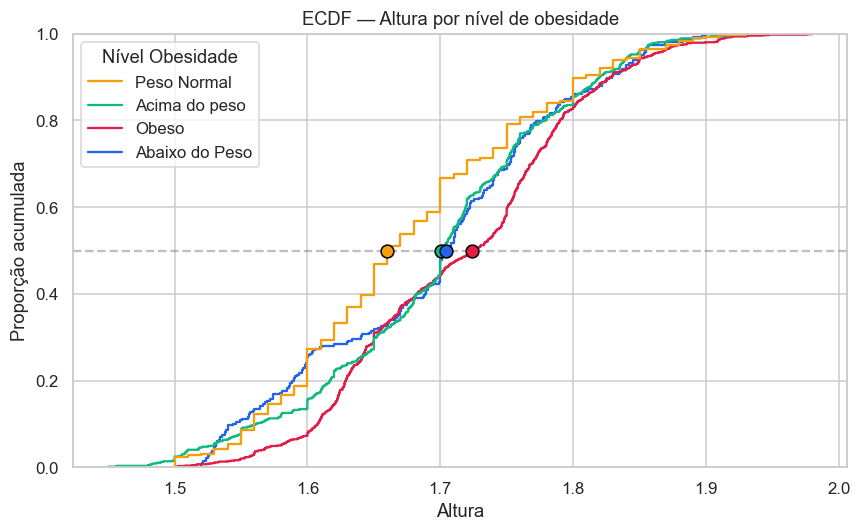

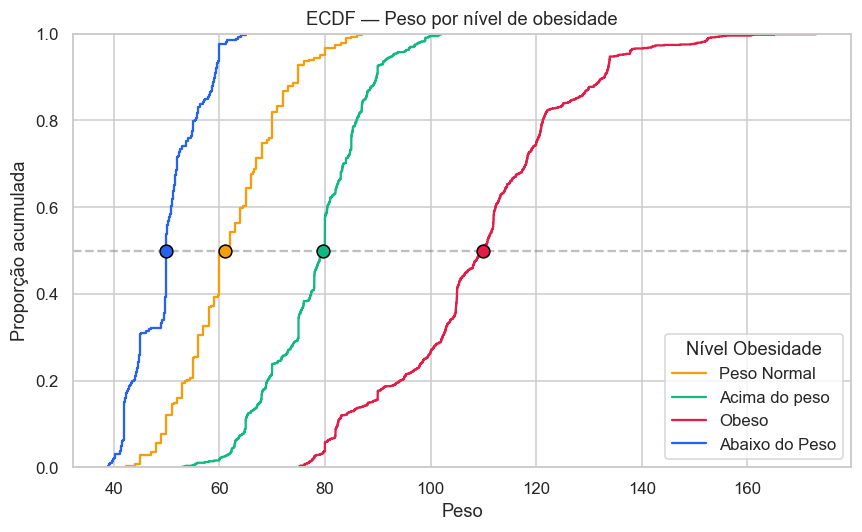

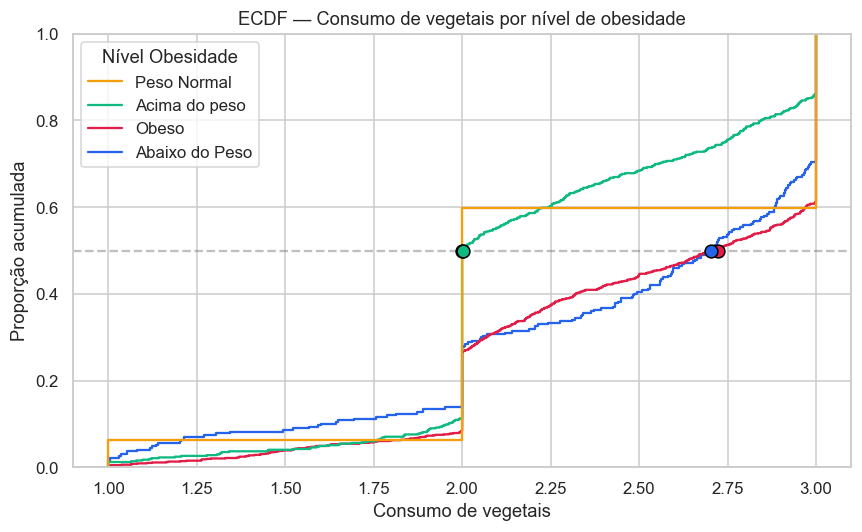

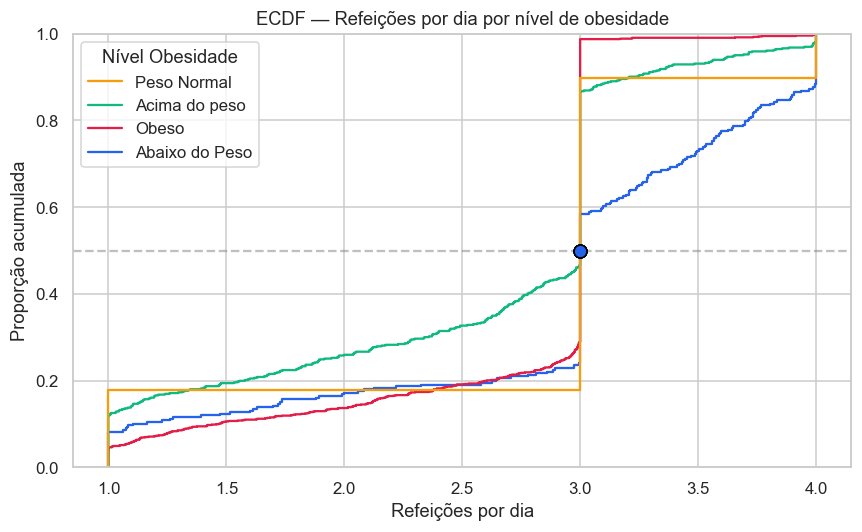

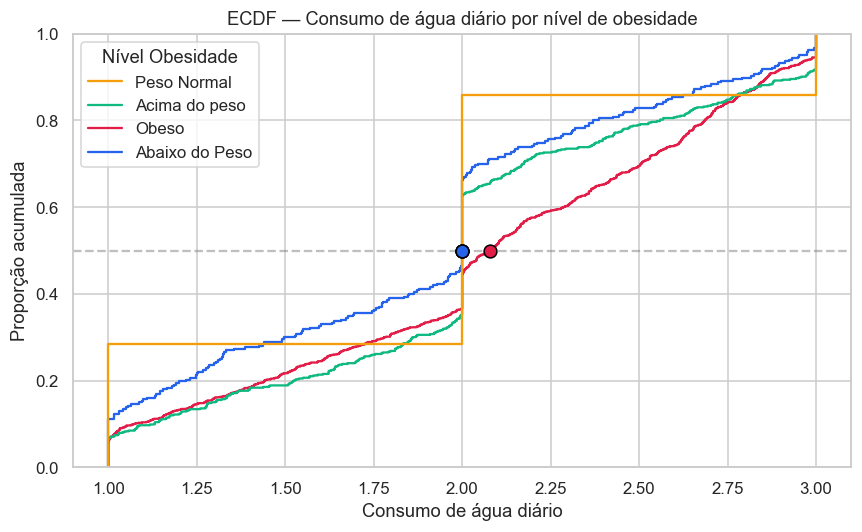

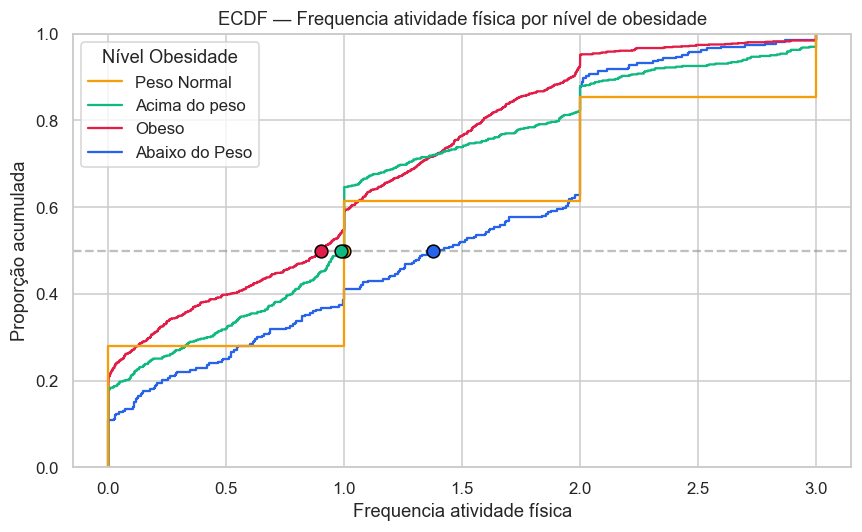

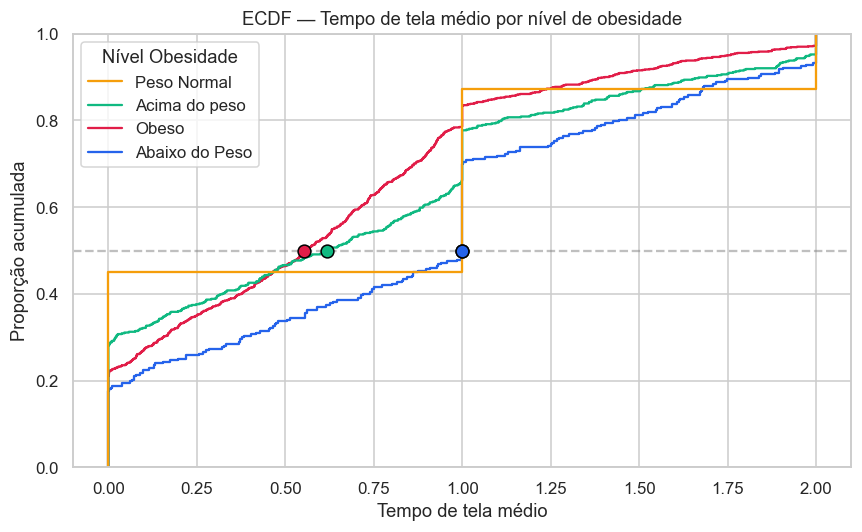

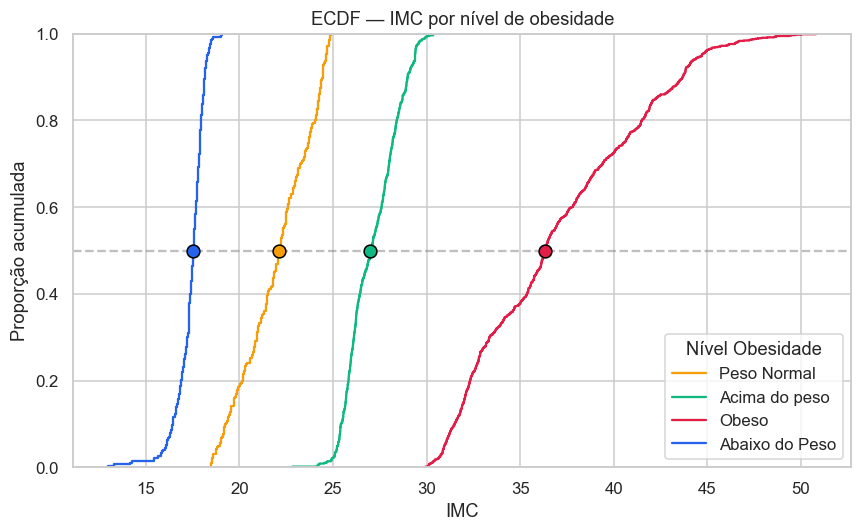

In [10]:

cores = {
            "Peso Normal": PN,
            "Acima do peso": AP,
            "Obeso": O,
            "Abaixo do Peso": AB}

for variavel in VARS_QUANT:

    plt.figure(figsize=(8, 5))

    sns.ecdfplot(
        data=df_clean,
        x=variavel,
        hue="Nível Obesidade",
        palette=cores
    )

    # Adiciona um ponto na mediana de cada categoria
    for classe, cor in cores.items():

        mediana = df_clean.loc[
            df_clean["Nível Obesidade"] == classe,
            variavel
        ].median()

        plt.scatter(
            mediana,
            0.5,
            color=cor,
            s=70,
            edgecolor="black",
            zorder=5
        )

    plt.axhline(0.5, color="gray", linestyle="--", alpha=0.5)

    plt.title(f"ECDF — {variavel} por nível de obesidade")
    plt.xlabel(variavel)
    plt.ylabel("Proporção acumulada")

    plt.tight_layout()
    plt.show()


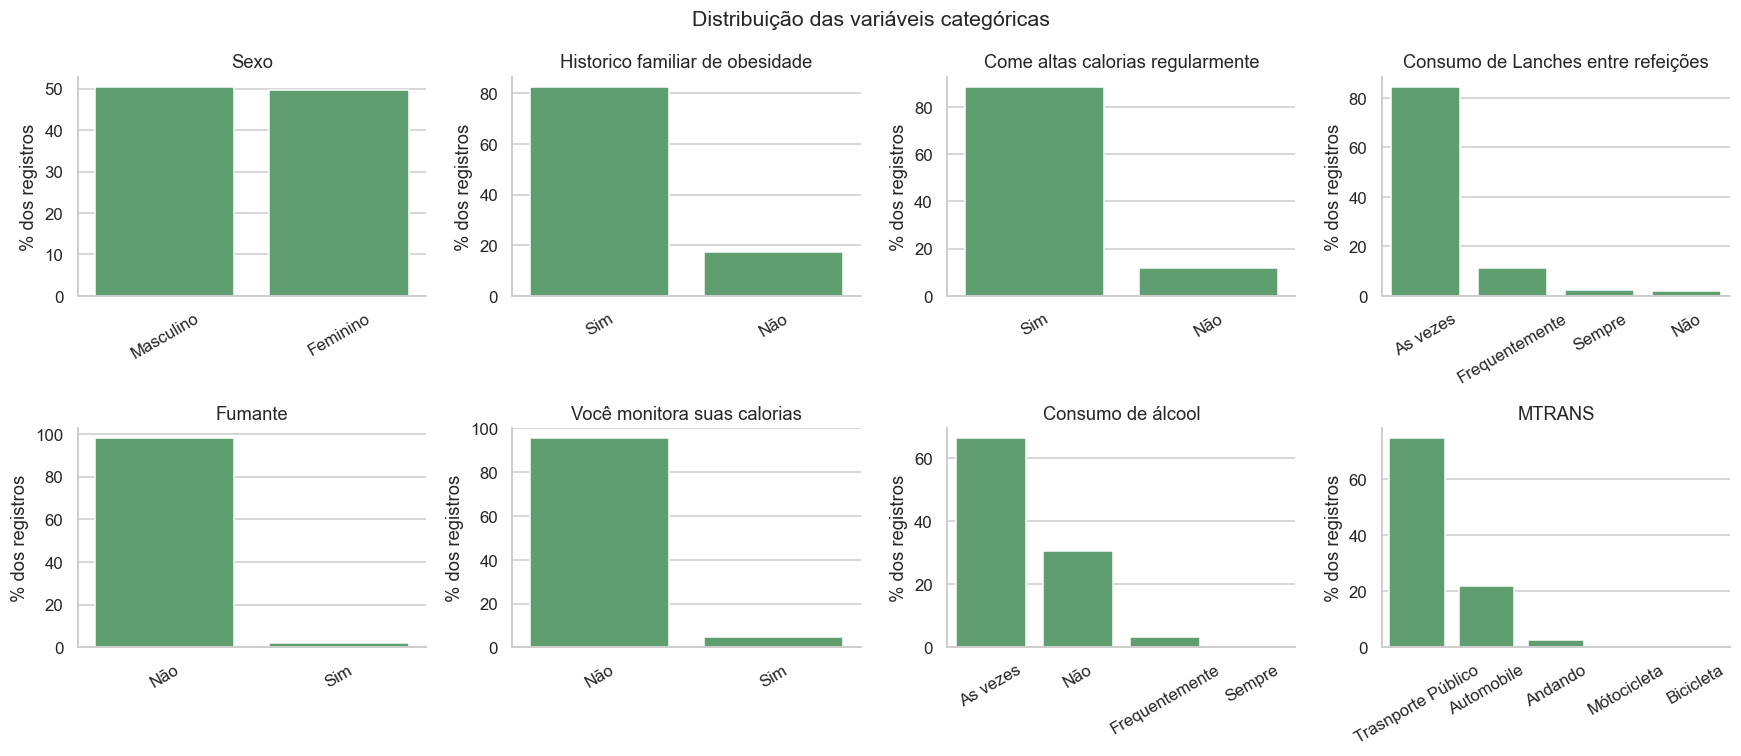

In [11]:
# [IA] Claude: frequências das variáveis categóricas
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, VARS_QUALI):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    vc = df[c].value_counts(normalize=True).mul(100)
    sns.barplot(x=vc.index, y=vc.values, ax=ax, color="#55A868")
    ax.set(title=c, xlabel="", ylabel="% dos registros")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Distribuição das variáveis categóricas", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C3_categoricas.png"); plt.show()

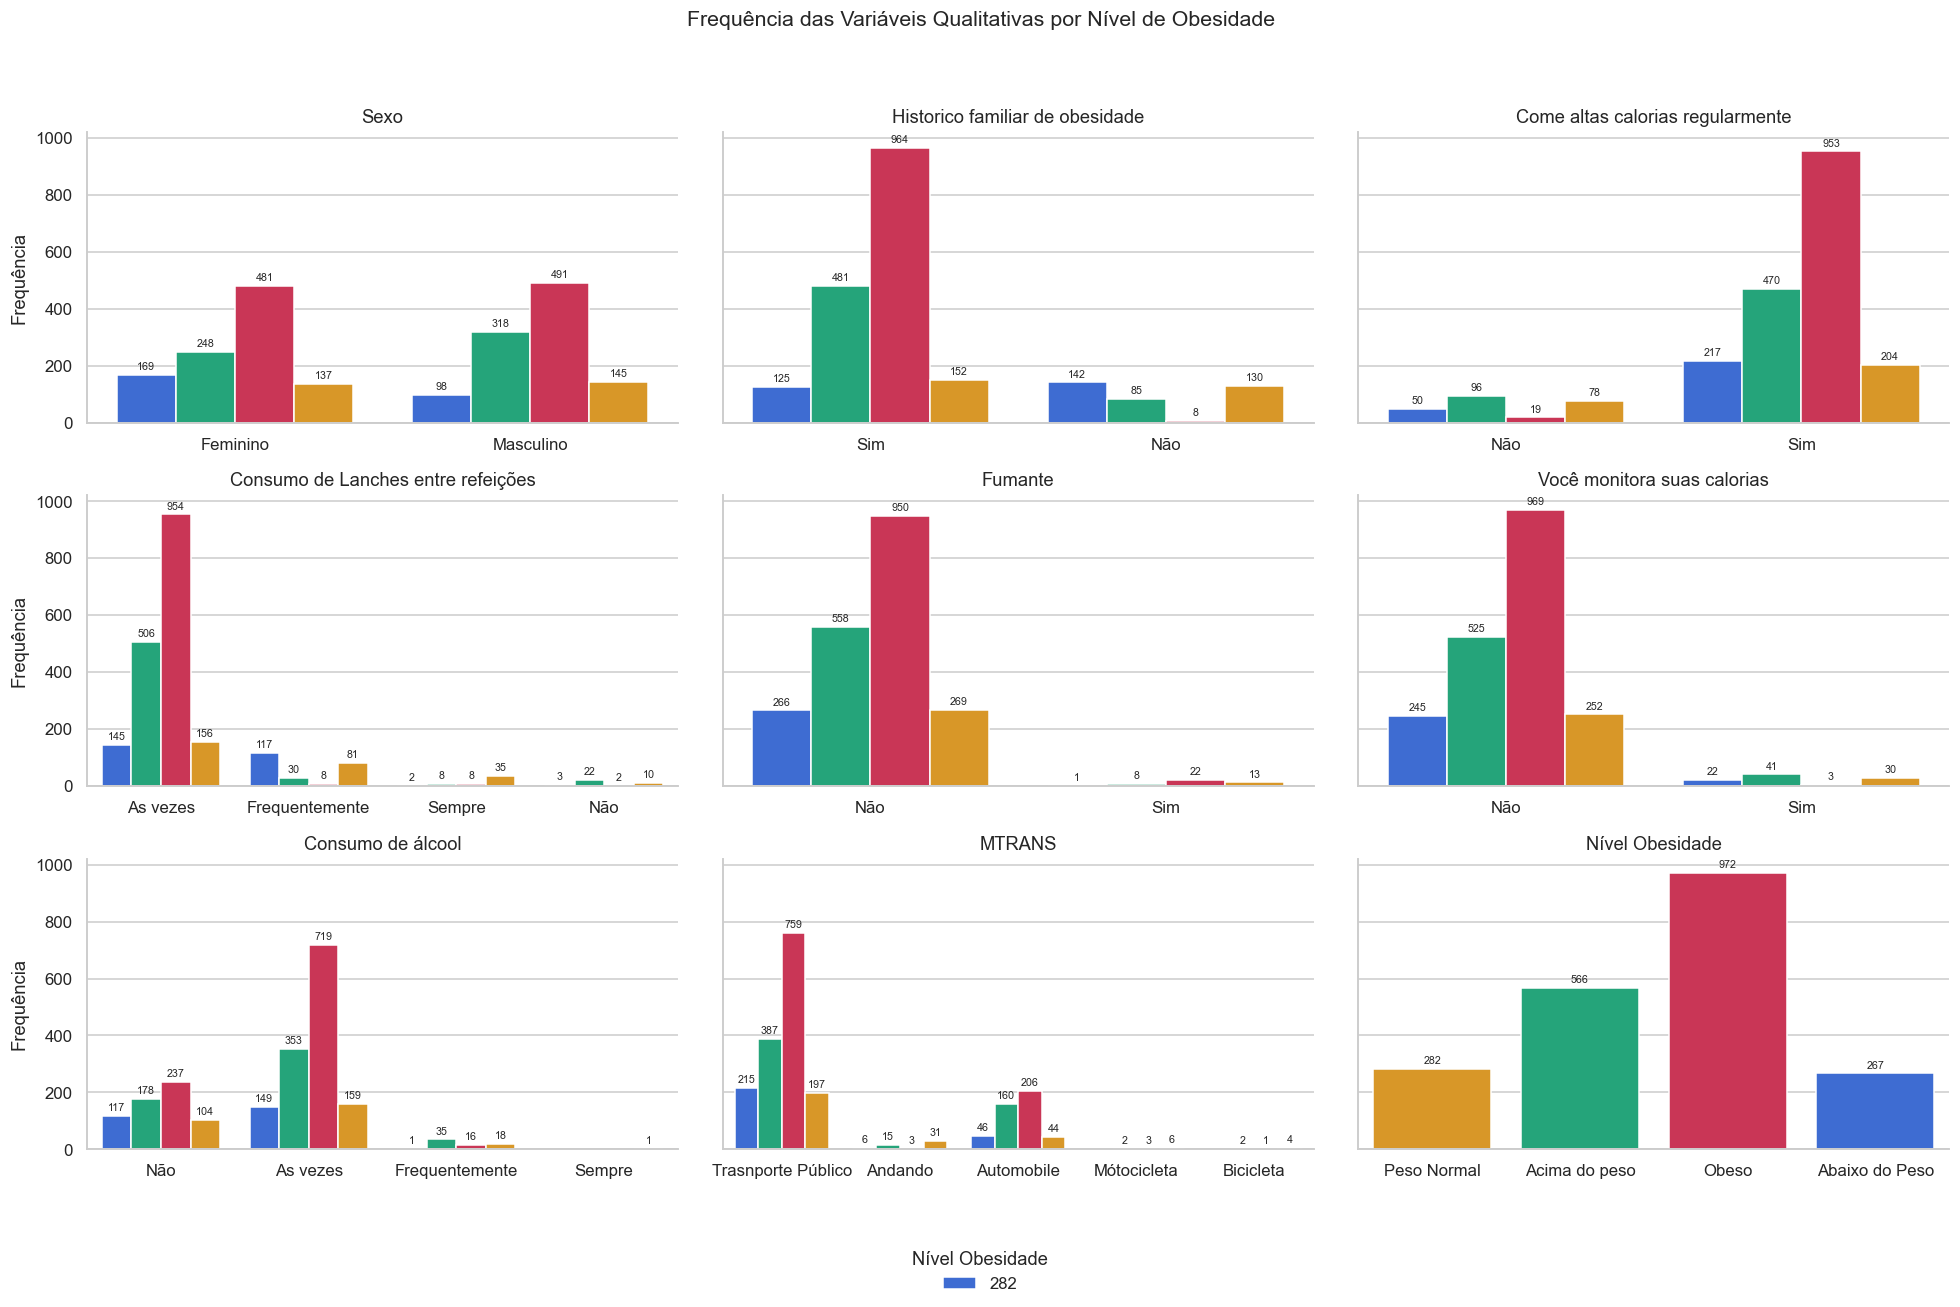

In [12]:

TARGET = "Nível Obesidade"

cores = {
            "Peso Normal": PN,
            "Acima do peso": AP,
            "Obeso": O,
            "Abaixo do Peso": AB}

# Identifica as classes reais
classes = sorted(df_clean[TARGET].dropna().unique(), key=str)

# Paleta com tonalidades suaves de azul
PALETA_AZUL = sns.color_palette(
    "Blues",
    n_colors=len(classes)
)

# Configuração dos gráficos
ncols = 3
nrows = math.ceil(len(VARS_QUALI) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 4 * nrows),
    sharey=True
)

axes = np.array(axes).ravel()

for i, col in enumerate(VARS_QUALI):

    ax = axes[i]
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    sns.countplot(
        data=df_clean,
        x=col,
        hue=TARGET,
        hue_order=classes,
        palette=cores,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Frequência")
    ax.tick_params(axis="x", rotation=0)

    # Adiciona os valores de frequência sobre as barras
    for container in ax.containers:
        labels = [
            f"{int(bar.get_height())}" if bar.get_height() > 0 else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=2,
            fontsize=7
        )

    # Guarda a legenda apenas do primeiro gráfico
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()

    legend = ax.get_legend()
    if legend:
        legend.remove()

# Desativa os gráficos vazios
for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

# Legenda geral
fig.legend(
    handles,
    labels,
    title=TARGET,
    loc="lower center",
    ncol=len(classes),
    frameon=False
)

fig.suptitle(
    "Frequência das Variáveis Qualitativas por Nível de Obesidade",
    fontsize=14
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

Teste de Aderência:

Shapiro Wilk não será utilizado pois o número da amostra é grande demais, pois o método não é adequado para tratar grande quantidade de dados

**O que as distribuições mostram**
- **Age** é assimétrica à direita: a maioria tem entre 18 e 26 anos e a cauda vai até 61. A amostra é jovem.
- **Weight** é larga, de 39 a 173 kg, com vários picos, um efeito das classes balanceadas. **Height** é quase simétrica.
- As ordinais (**FCVC, NCP, CH2O, FAF e TUE**) concentram valores nos inteiros 1, 2 e 3, com uma "nuvem" de decimais entre eles, que é a marca do SMOTE.
- Nas categóricas, **SMOKE** e **SCC** são muito raras, com menos de 5% de "yes". A maioria tem histórico familiar de sobrepeso e consome alimentos calóricos (FAVC). Em **MTRANS** predominam o transporte público e o automóvel.

## 2. EDA, pilar 2: dispersão

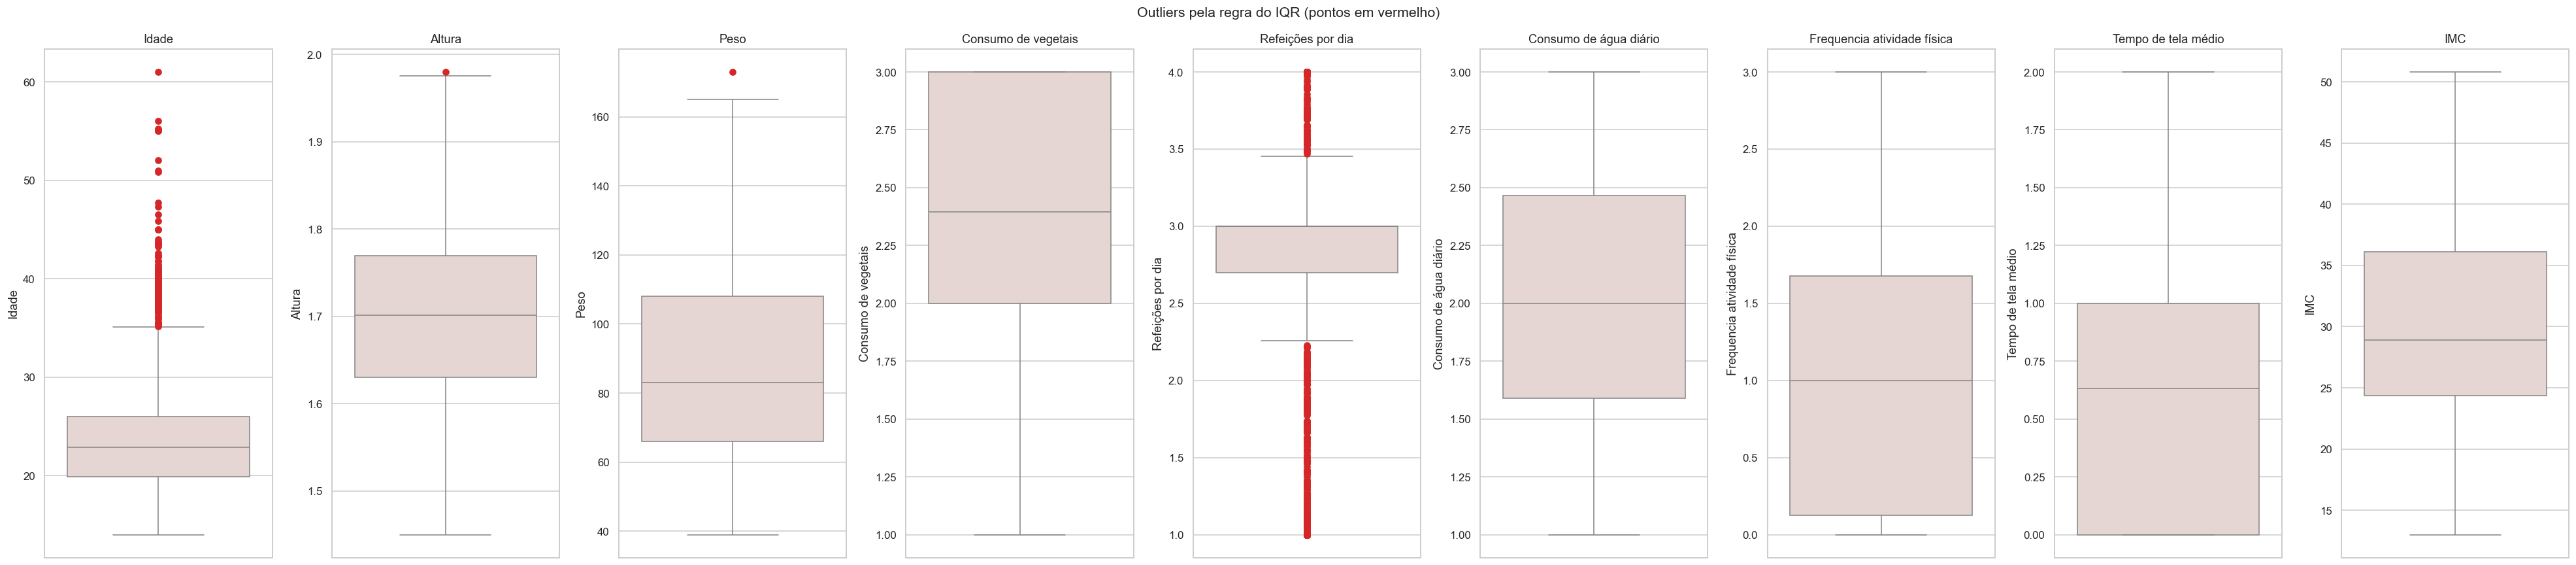

In [13]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 8))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df_clean, y=col, color=COR_CONTEXTO,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

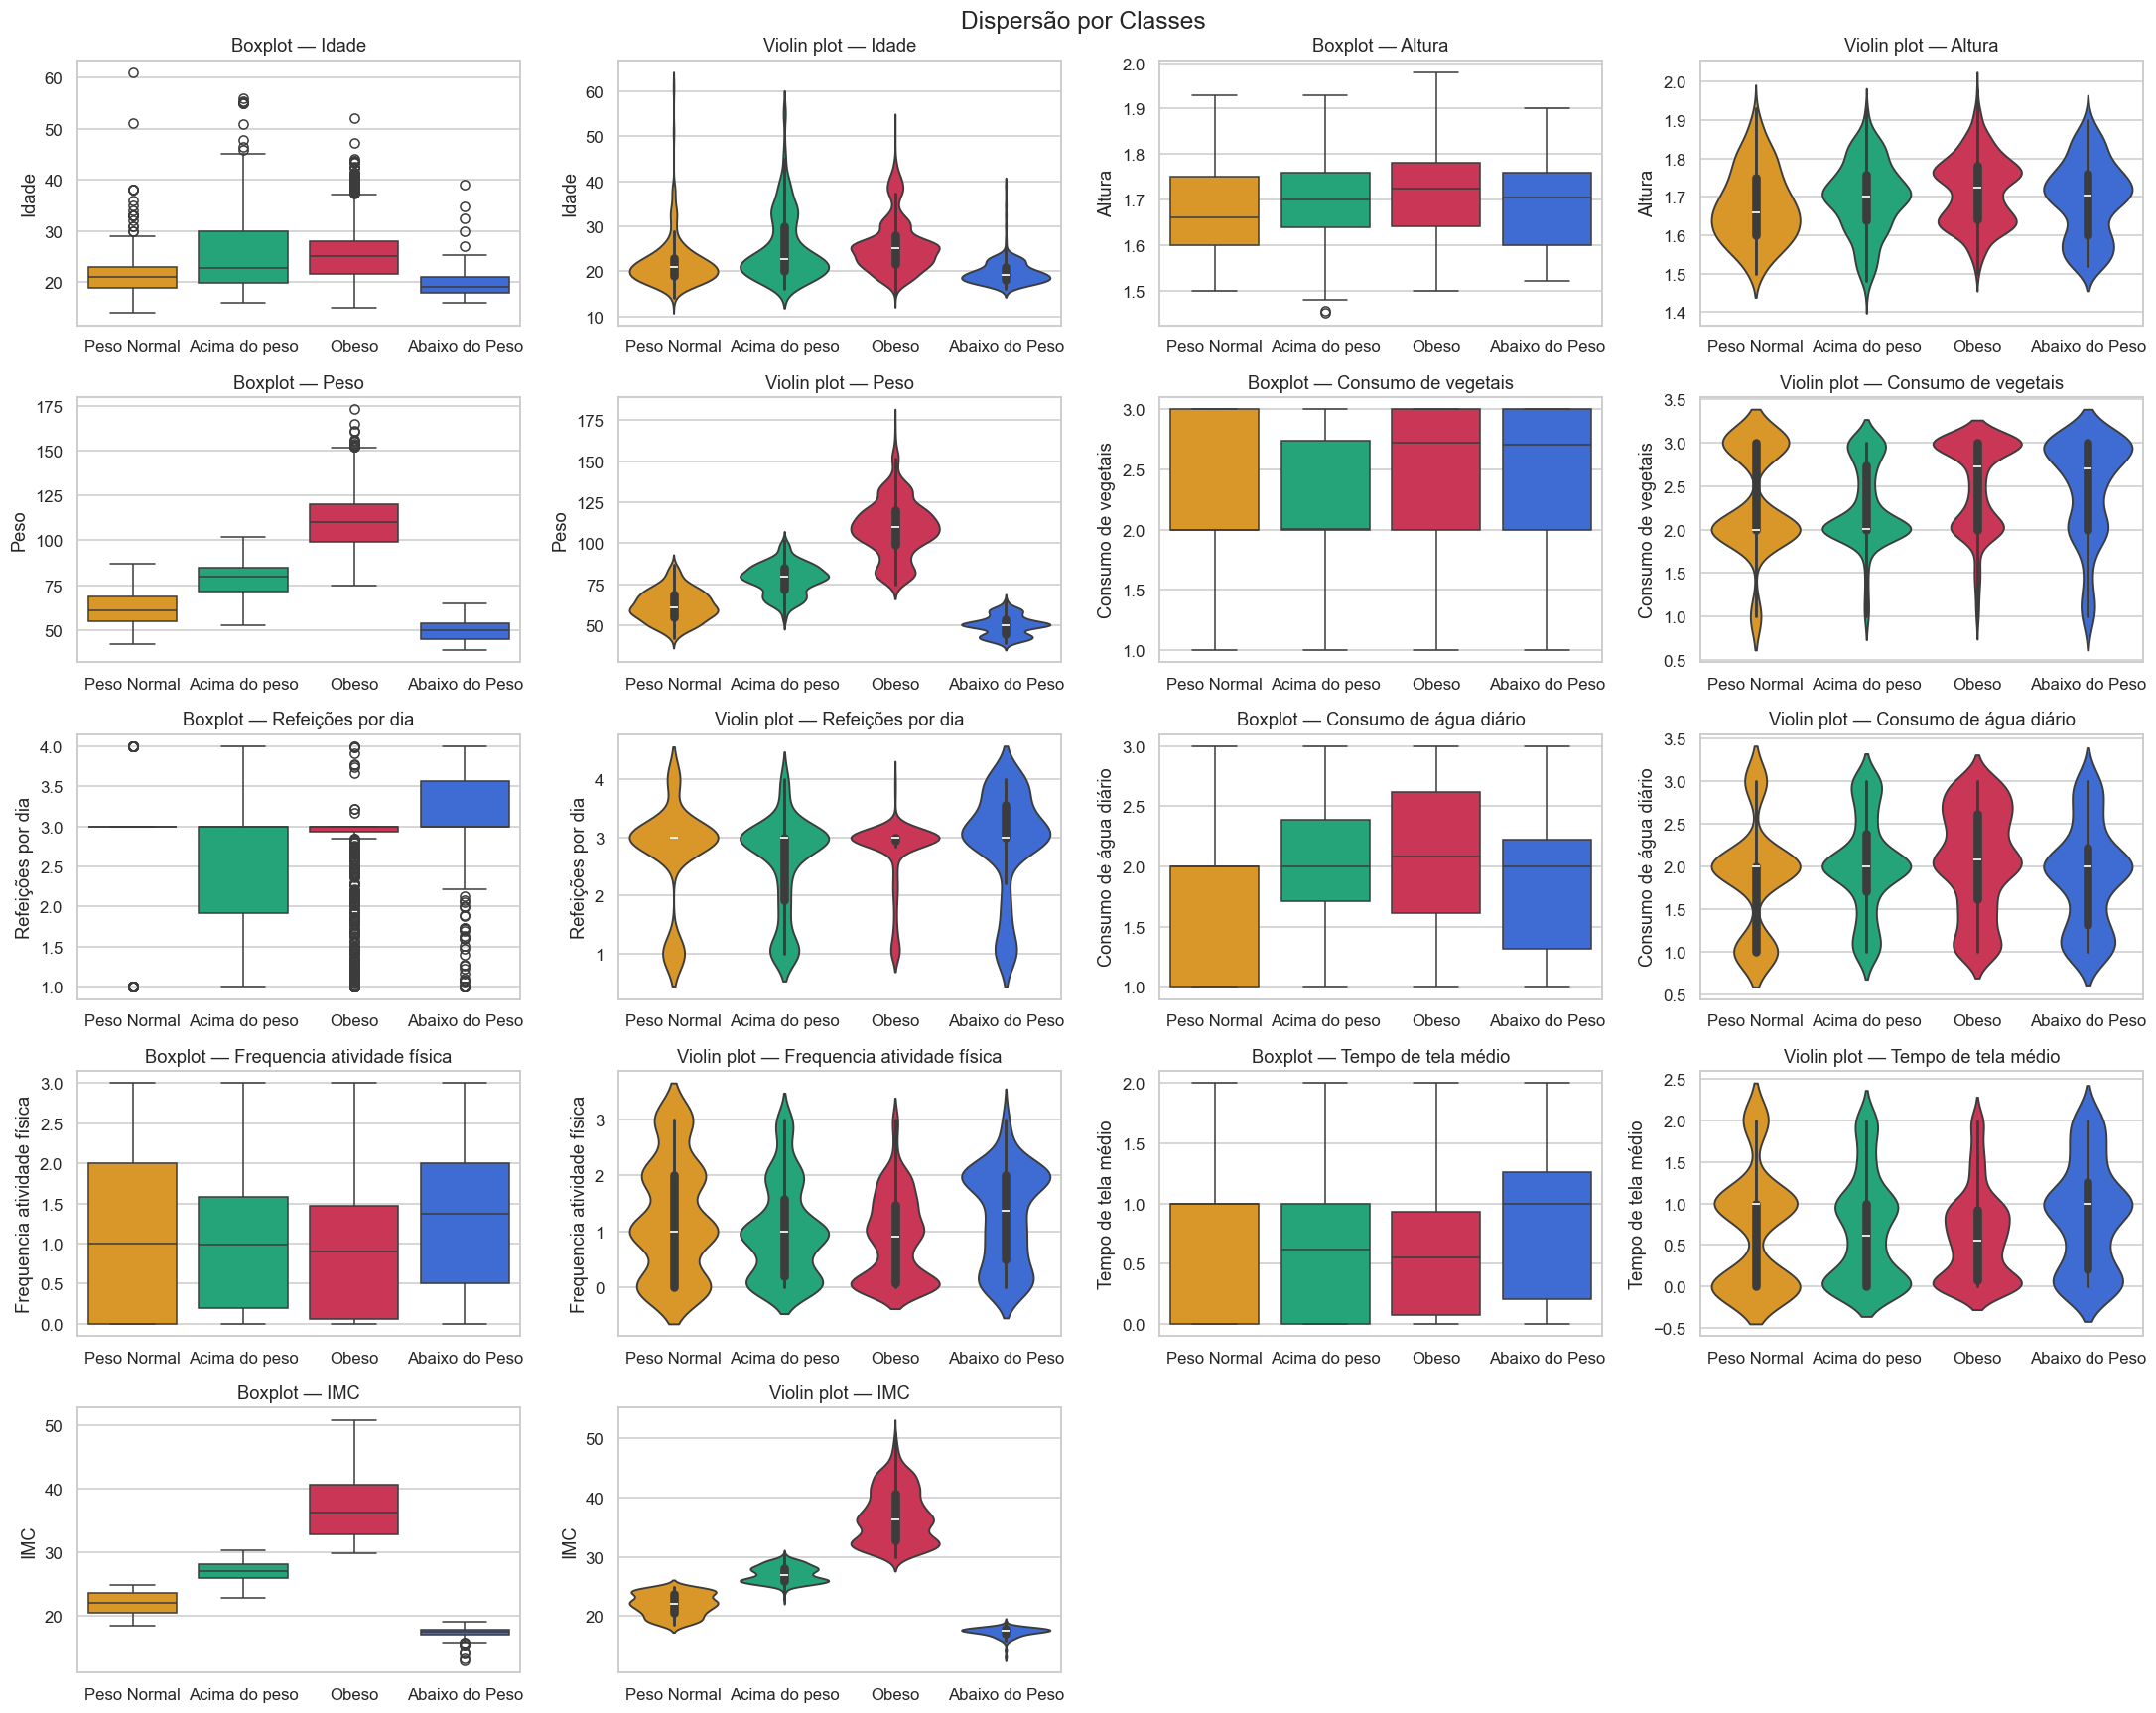

In [14]:

"""### Boxplot e violin plot por classe"""


fig, axes = plt.subplots(
    5, 4,
    figsize=(20, 16)
)

for i, col in enumerate(VARS_QUANT):

    linha = i // 2
    coluna = (i % 2) * 2

    # Boxplot
    sns.boxplot(
        data=df_clean,
        x="Nível Obesidade",
        y=col,
        hue="Nível Obesidade",
        palette=cores,
        legend=False,
        ax=axes[linha, coluna]
    )

    axes[linha, coluna].set_title(f"Boxplot — {col}")
    axes[linha, coluna].set_xlabel("")

    # Violin plot
    sns.violinplot(
        data=df_clean,
        x="Nível Obesidade",
        y=col,
        hue="Nível Obesidade",
        palette=cores,
        legend=False,
        ax=axes[linha, coluna + 1]
    )

    axes[linha, coluna + 1].set_title(f"Violin plot — {col}")
    axes[linha, coluna + 1].set_xlabel("")

fig.suptitle(
    "Dispersão por Classes",
    fontsize=16
)
for ax in axes.ravel()[2 * len(VARS_QUANT):]:
    ax.set_axis_off()

plt.tight_layout()
plt.show()


## 3. EDA, pilar 3: relações

In [15]:
def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df_clean[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Sexo,2.0,1.02,1.000
Historico familiar de obesidade,2.0,4.72,0.669
Come altas calorias regularmente,2.0,7.59,0.519
Consumo de Lanches entre refeições,4.0,47.59,0.400
Fumante,2.0,46.43,0.147
Você monitora suas calorias,2.0,20.74,0.269
Consumo de álcool,4.0,1380.00,0.543
MTRANS,5.0,222.57,0.431
Nível Obesidade,4.0,3.64,0.897


Desbalanceamento (Claramente algumas estão EXTREMAMENTE desbalanceadas)

In [16]:
print(df_clean['Fumante'].value_counts())
print("\n")
print(df_clean['Você monitora suas calorias'].value_counts())
print("\n")
print(df_clean['Consumo de álcool'].value_counts())
print("\n")
print(df_clean['MTRANS'].value_counts())

Fumante
Não    2043
Sim      44
Name: count, dtype: int64


Você monitora suas calorias
Não    1991
Sim      96
Name: count, dtype: int64


Consumo de álcool
As vezes          1380
Não                636
Frequentemente      70
Sempre               1
Name: count, dtype: int64


MTRANS
Trasnporte Público    1558
Automobile             456
Andando                 55
Mótocicleta             11
Bicicleta                7
Name: count, dtype: int64


Serão retirados as classificações: Sempre (Consumuo de Álcool), Bicicleta(MTRANS) e Motocicleta (MTRANS)
Justificações: Tem tão poucos valores nessas categorias (0,047%, 0.521% e 0.331%, respectivamente) que não podemos comprovar se eles tem qualquer tipo de relação ou influência com as outras variáveis. Além disso, eles podem facilmente desbalancear distorcer a análise bivariada e possivelmente o modelo

In [17]:
df = df_clean[
    ~df_clean["Consumo de álcool"].isin([
        "Sempre"
    ]) &
    ~df_clean["MTRANS"].isin([
        "Mótocicleta",
        "Bicicleta"
    ])
].copy()


df_K = df_K[
    ~df_K["CALC"].isin([
        "Always"
    ]) &
    ~df_K["MTRANS"].isin([
        "Motorbike",
        "Bike"
    ])
].copy()



In [18]:
print(f"Registros originais: {len(df_clean)}")
print(f"Registros restantes: {len(df)}")
print(f"Registros removidos: {len(df_clean) - len(df)}")


Registros originais: 2087
Registros restantes: 2068
Registros removidos: 19


In [19]:
print("Novo valores de Desbalanceamento")
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

Novo valores de Desbalanceamento


,n_classes,razao_desbalanceamento,entropia_normalizada
Sexo,2.0,1.00,1.000
Historico familiar de obesidade,2.0,4.78,0.665
Come altas calorias regularmente,2.0,7.76,0.512
Consumo de Lanches entre refeições,4.0,47.30,0.396
Fumante,2.0,47.09,0.146
Você monitora suas calorias,2.0,21.24,0.265
Consumo de álcool,3.0,19.57,0.682
MTRANS,3.0,28.85,0.584
Nível Obesidade,4.0,3.63,0.894


Consegue-se notar uma clara diferença na difetencia entre a razão de desbalanceamento entre as razao_desbalanceamento	e entropia_normalizada antigas e novas, mesmo removendo apenas 19 dados (Aproximadamente 0,90% do total) (focar em especial no Consumo de Álcool, teve a maior mudança mesmo removendo apena UM valor)

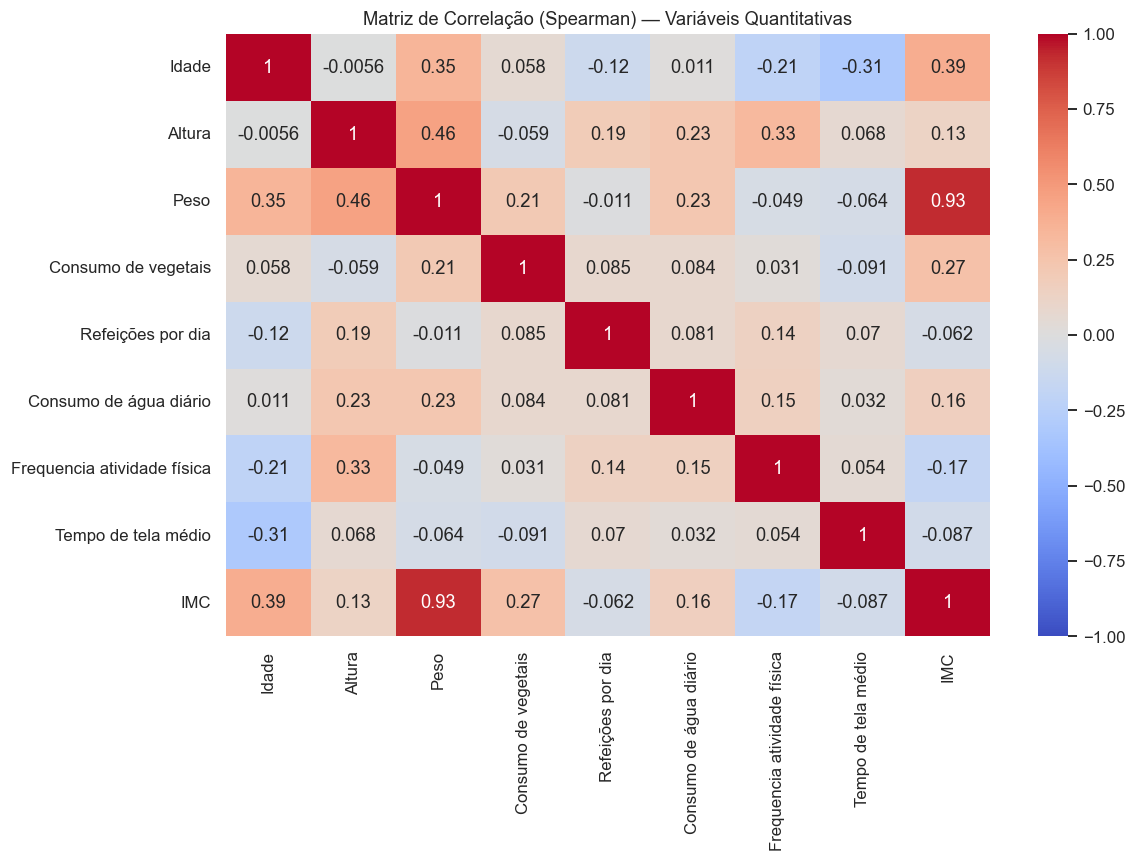

In [20]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")


plt.figure(figsize=(11, 8))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

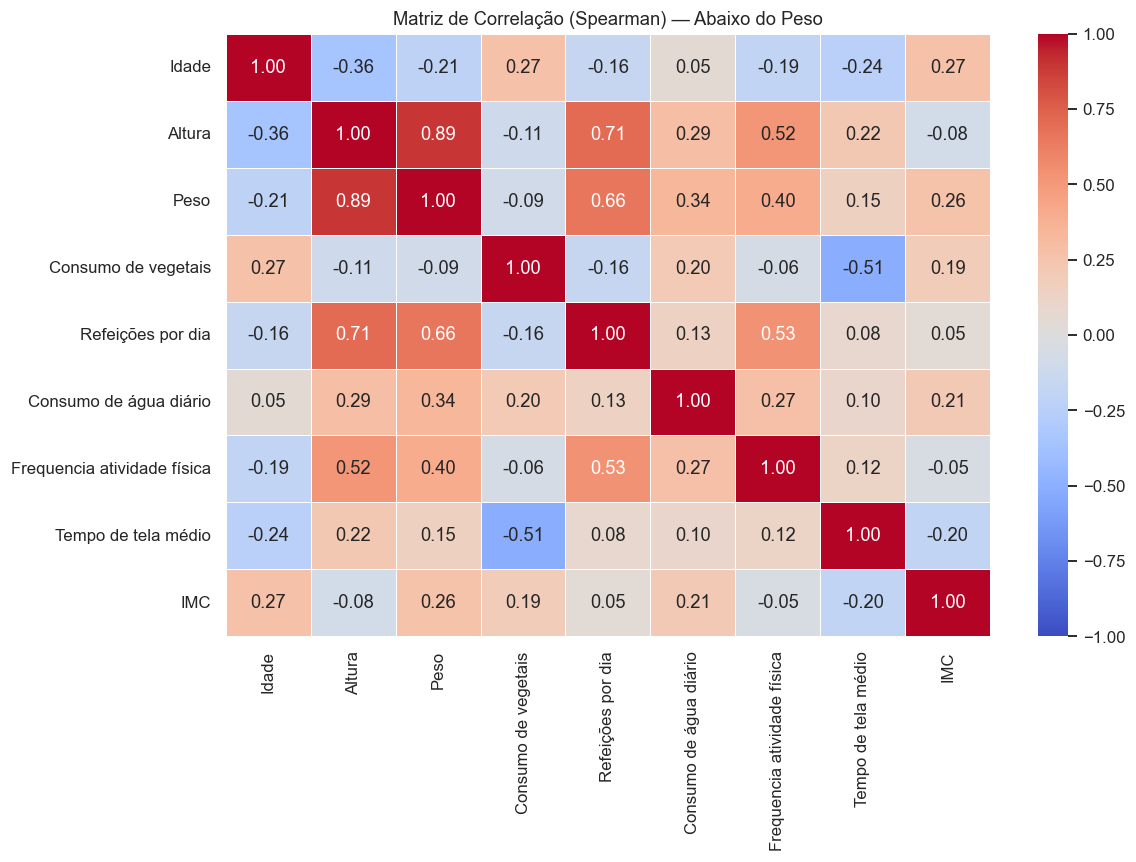

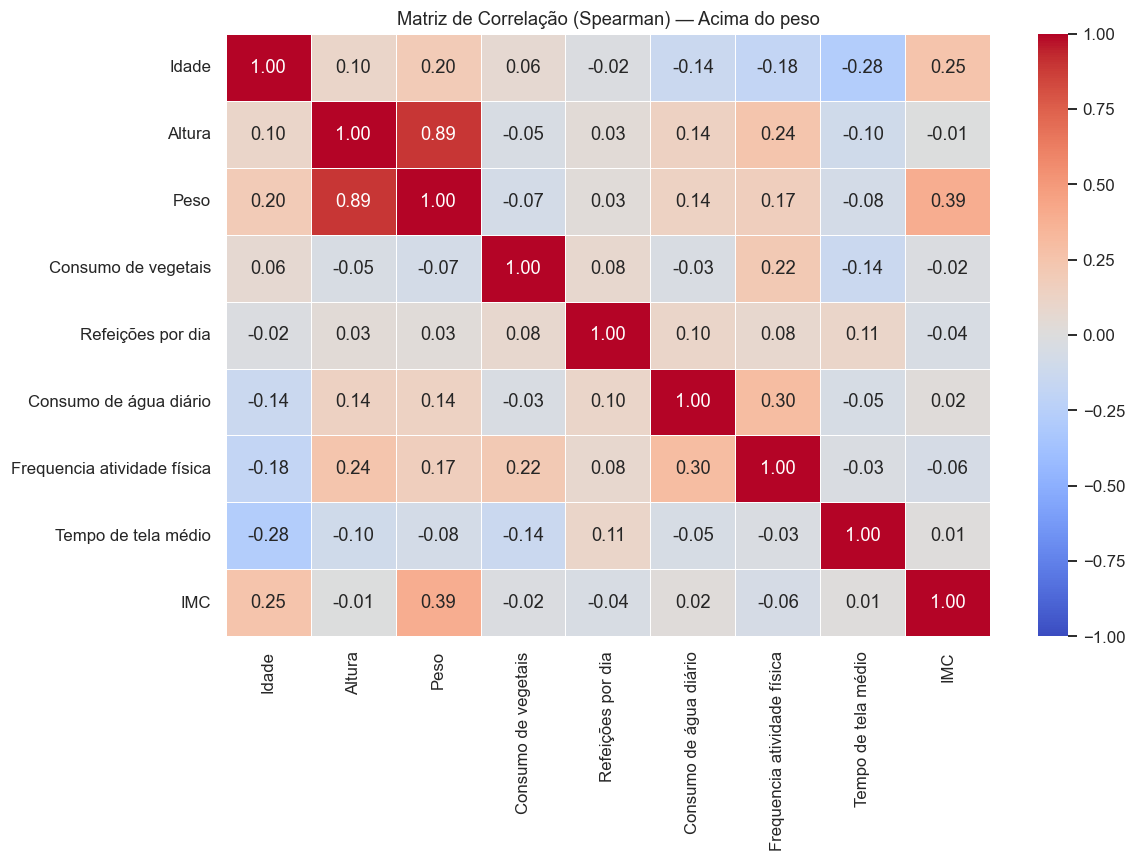

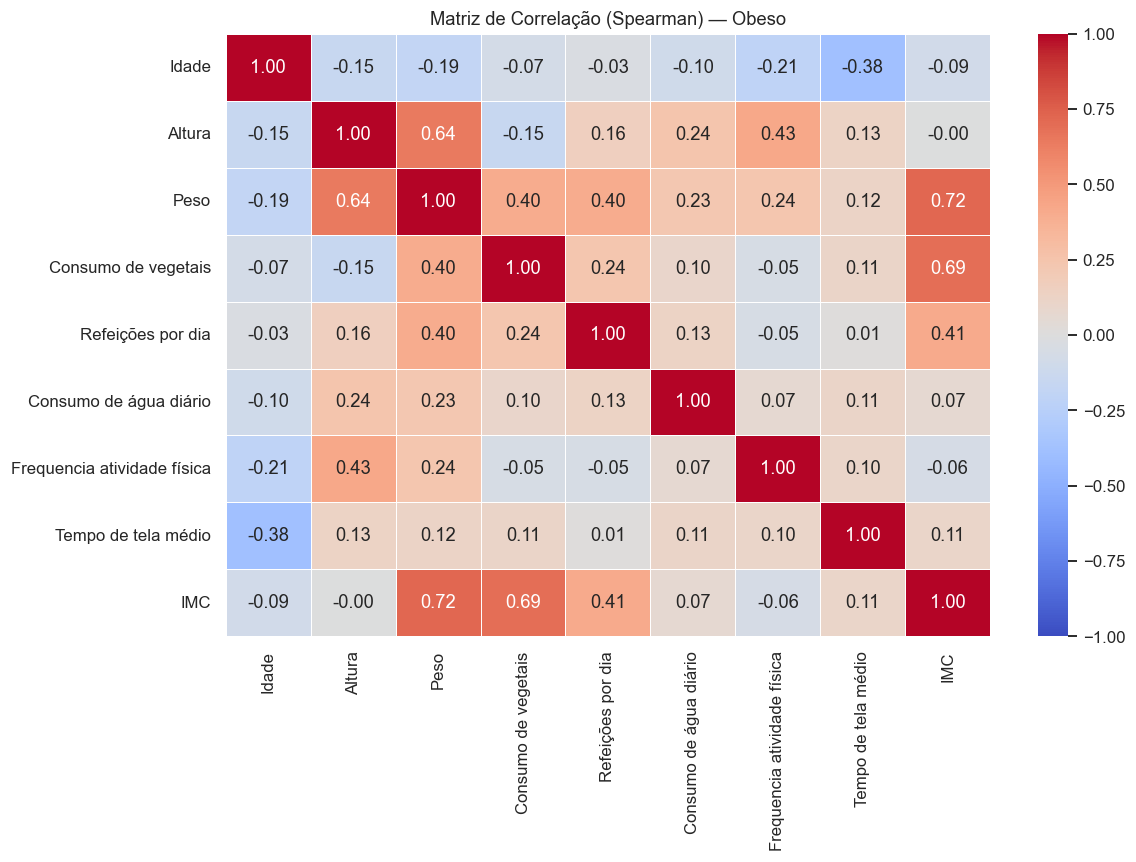

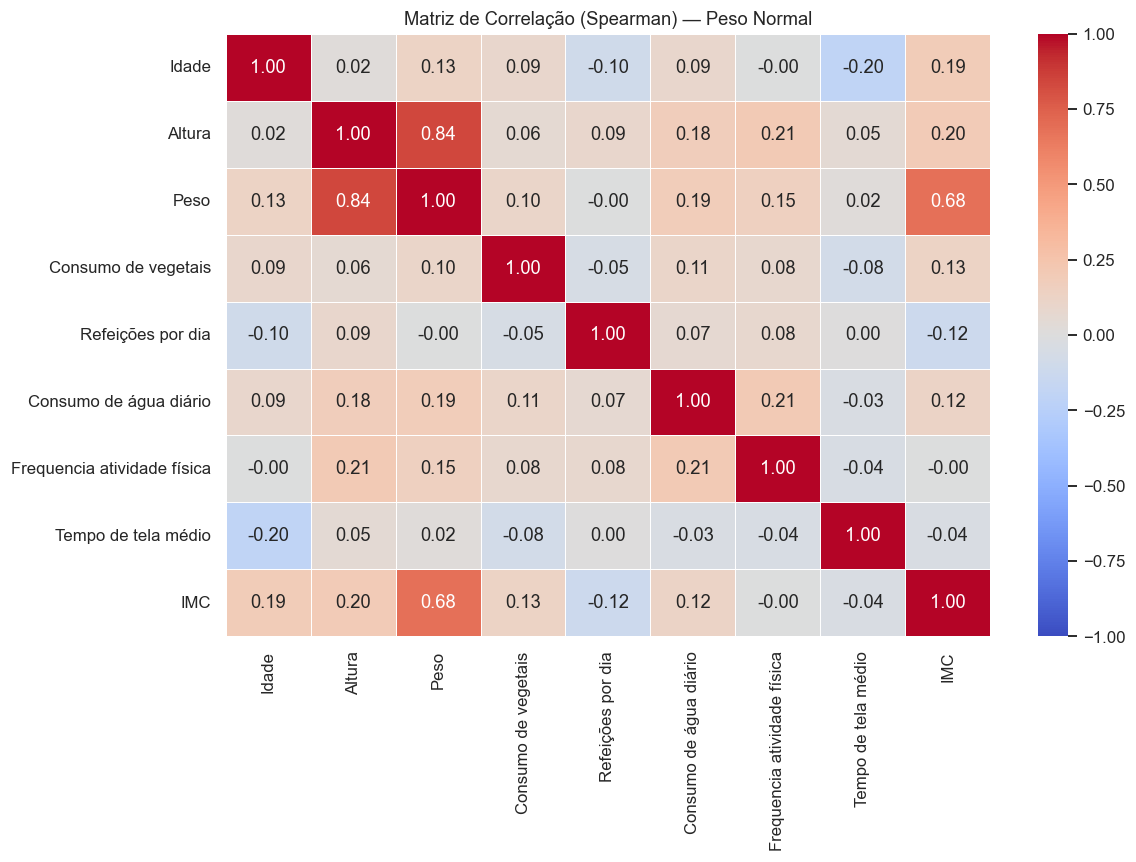

In [21]:
"""### Matrizes de Correlação Spearman por Nível de Obesidade"""

for classe, grupo in df.groupby("Nível Obesidade"):

    corr_spearman = grupo[VARS_QUANT].corr(method="spearman")
    # O método de spearman foi escolhido principalmente por essa relação não exigir linearidade ou uma distribuição normal dos dados

    plt.figure(figsize=(11, 8))

    sns.heatmap(
        corr_spearman,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1,
        center=0,
        linewidths=0.5
    )

    plt.title(f"Matriz de Correlação (Spearman) — {classe}")
    plt.tight_layout()
    plt.show()

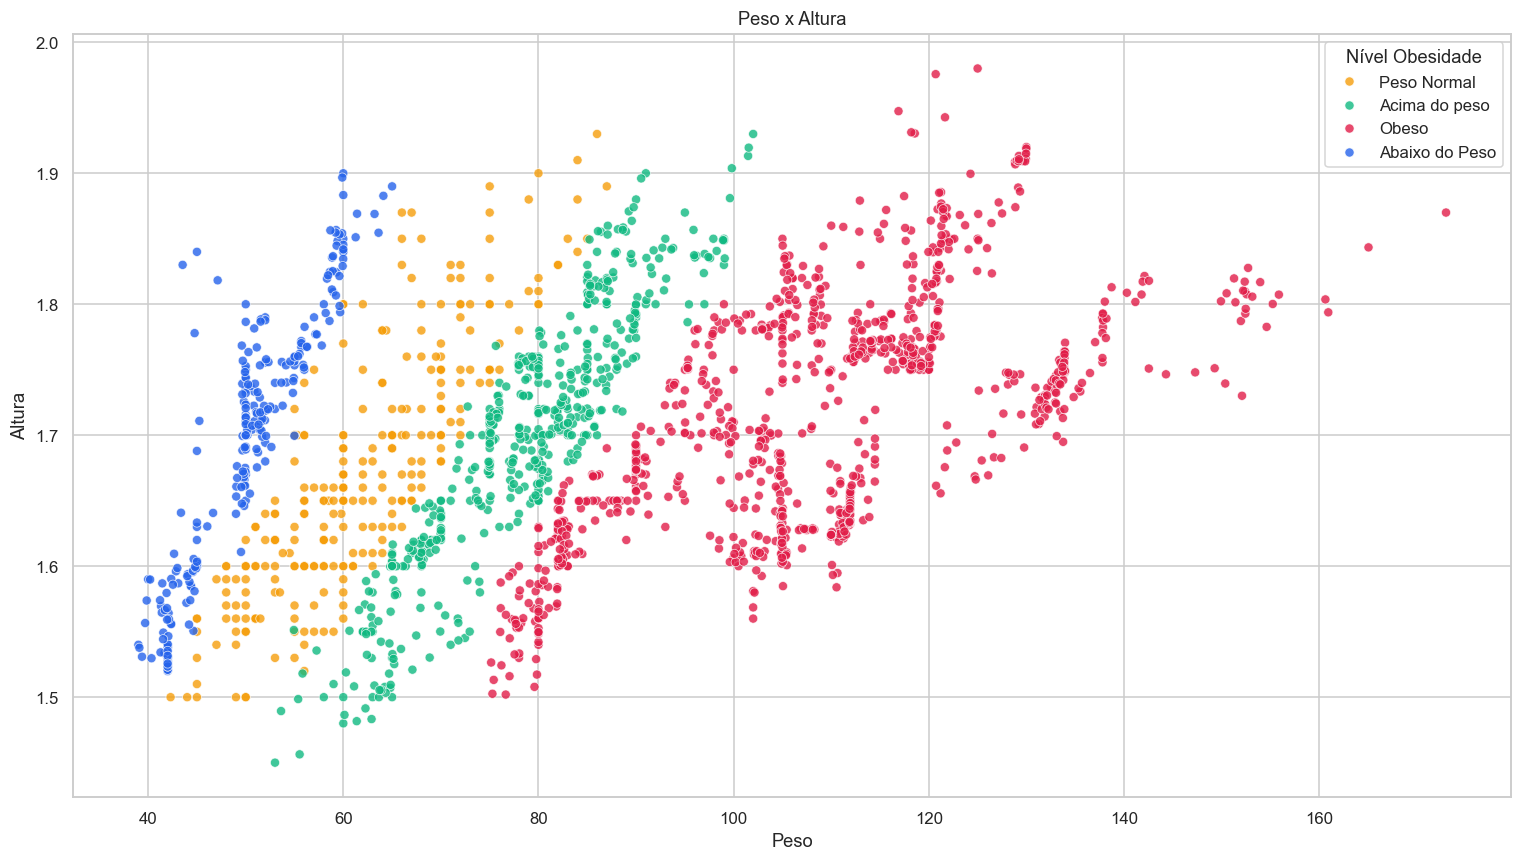

In [22]:
palette_classe_distribuição = {
    "Abaixo do Peso": "#2563EB",
    "Peso Normal": "#F59E0B",
    "Acima do peso": "#10B981",
    "Obeso": "#E11D48"
}

plt.figure(figsize=(14, 8))
sns.scatterplot(data=df, x="Peso", y="Altura", hue="Nível Obesidade",
                palette=palette_classe_distribuição, alpha=0.8)
plt.title("Peso x Altura")
plt.xlabel("Peso")
plt.ylabel("Altura")
plt.tight_layout()
plt.show()
# Lembrar de consertar a ordem na legenda no canto superior direito

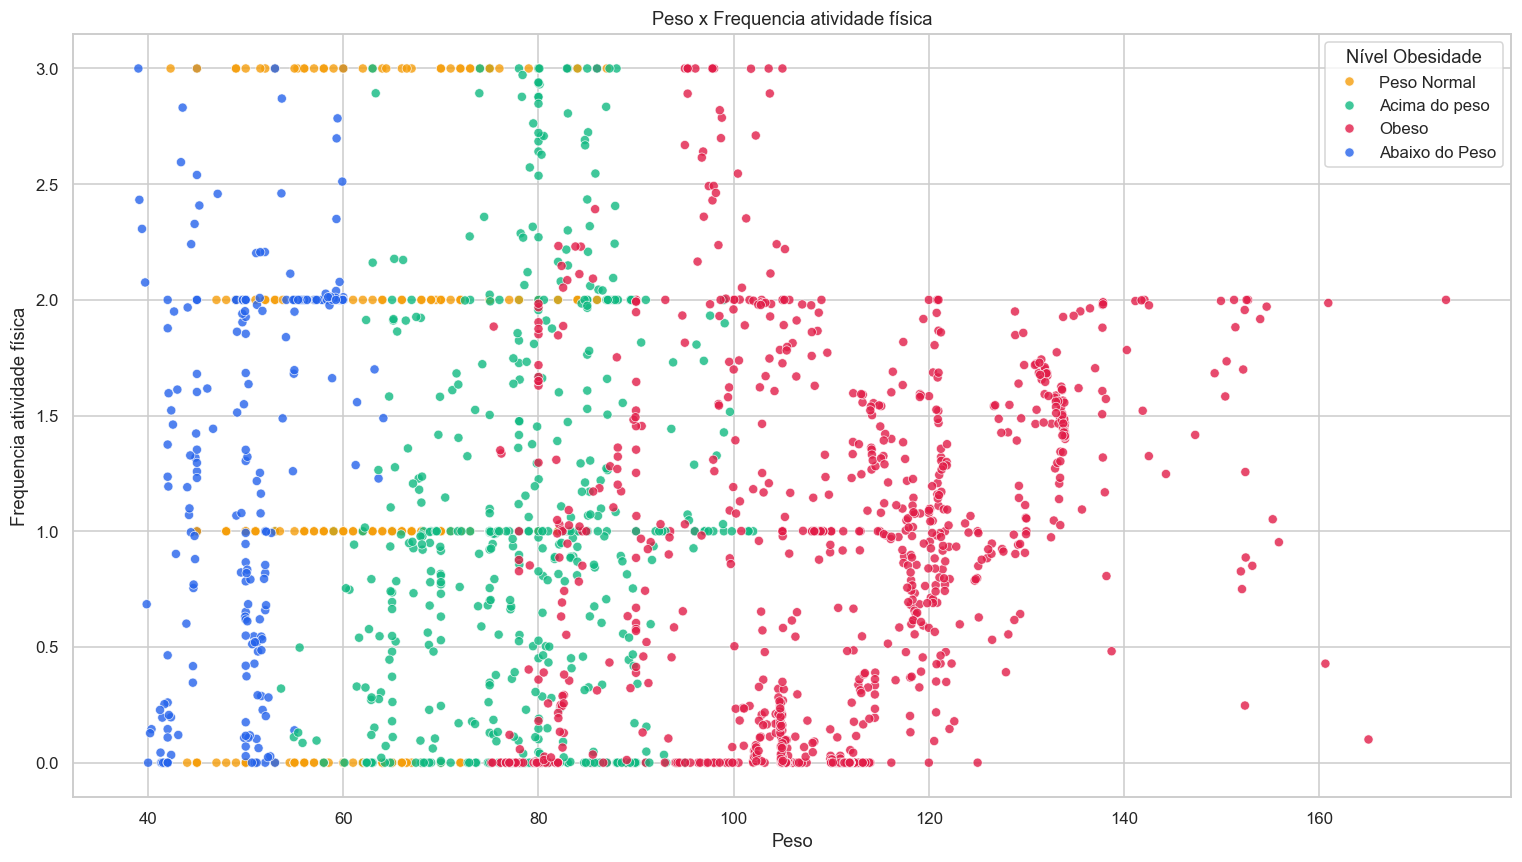

In [23]:
plt.figure(figsize=(14, 8))
sns.scatterplot(data=df, x="Peso", y="Frequencia atividade física", hue="Nível Obesidade",
                palette=palette_classe_distribuição, alpha=0.8)
plt.title("Peso x Frequencia atividade física")
plt.xlabel("Peso")
plt.ylabel("Frequencia atividade física")
plt.tight_layout()
plt.show()

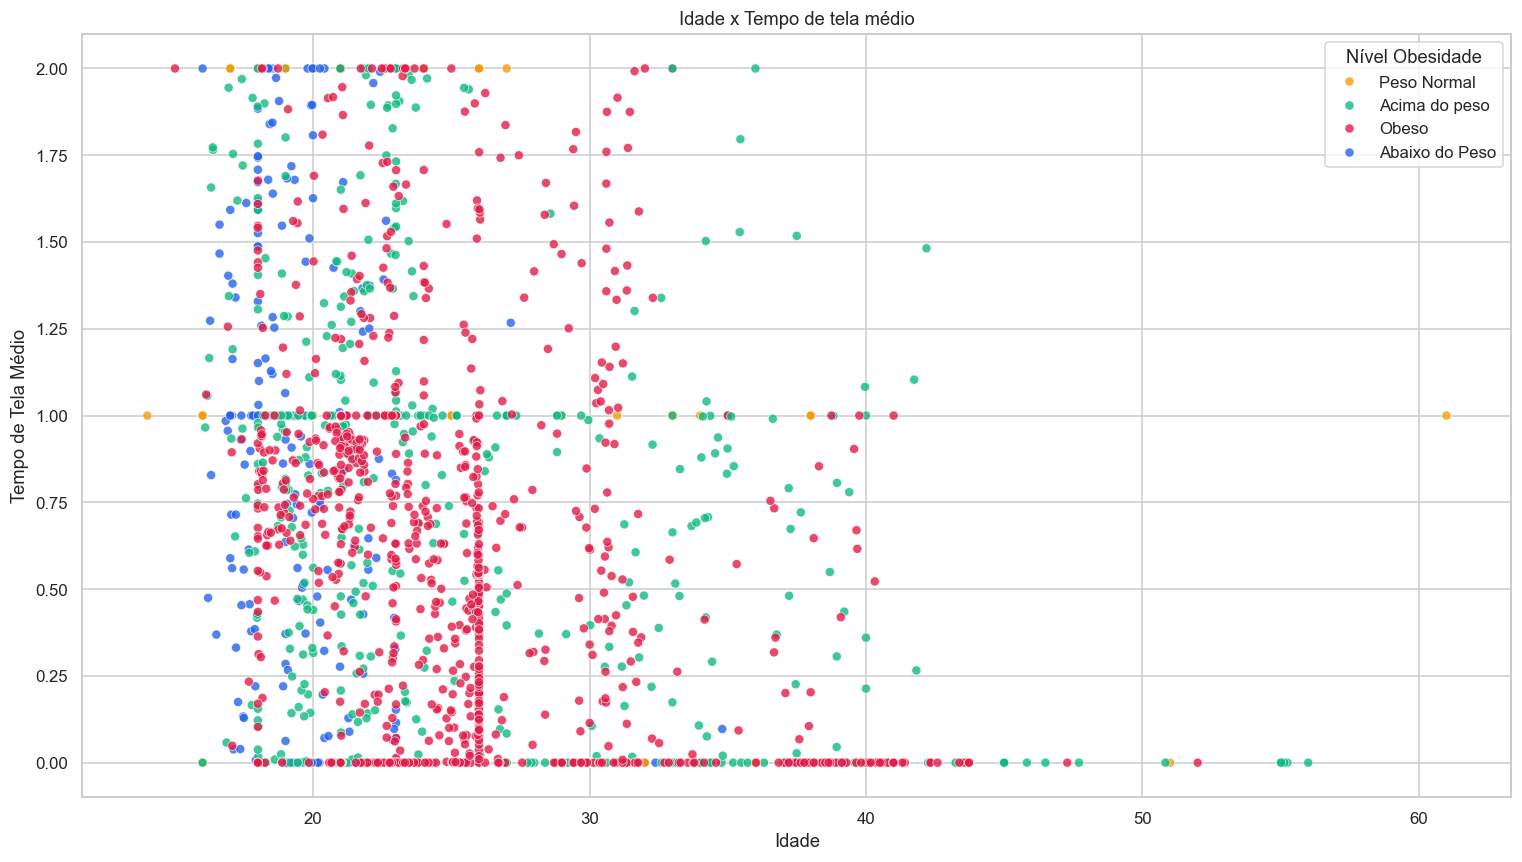

In [24]:
palette_classe_distribuição = {
    "Abaixo do Peso": "#2563EB",
    "Peso Normal": "#F59E0B",
    "Acima do peso": "#10B981",
    "Obeso": "#E11D48"
}

plt.figure(figsize=(14, 8))
sns.scatterplot(data=df, x="Idade", y="Tempo de tela médio", hue="Nível Obesidade",
                palette=palette_classe_distribuição, alpha=0.8)
plt.title("Idade x Tempo de tela médio")
plt.xlabel("Idade")
plt.ylabel("Tempo de Tela Médio")
plt.tight_layout()
plt.show()

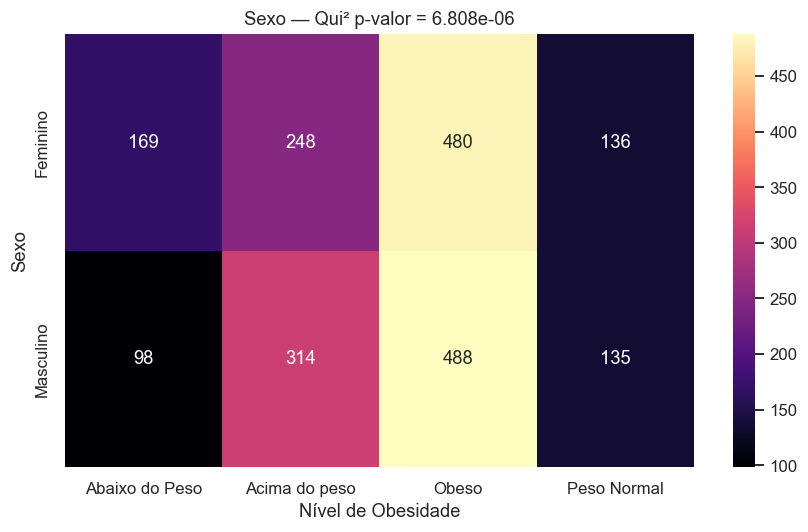

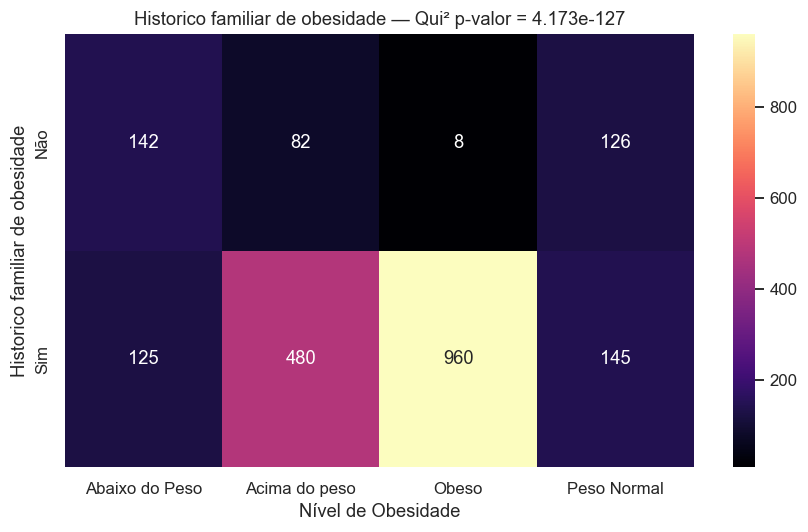

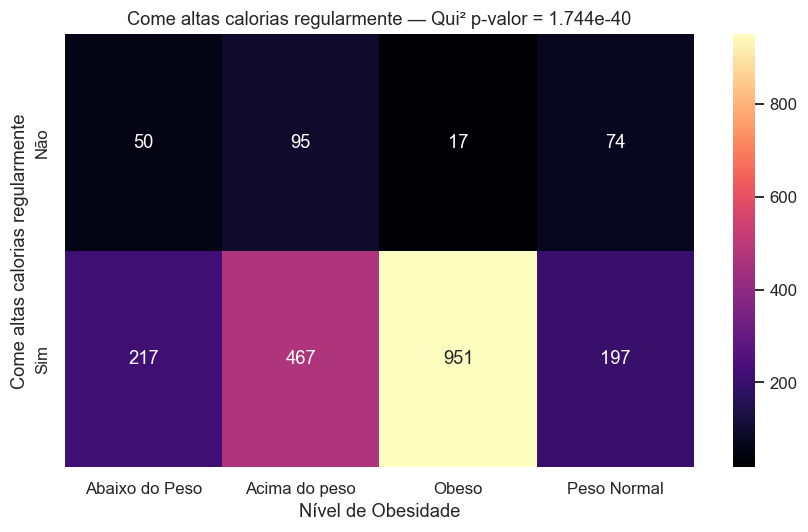

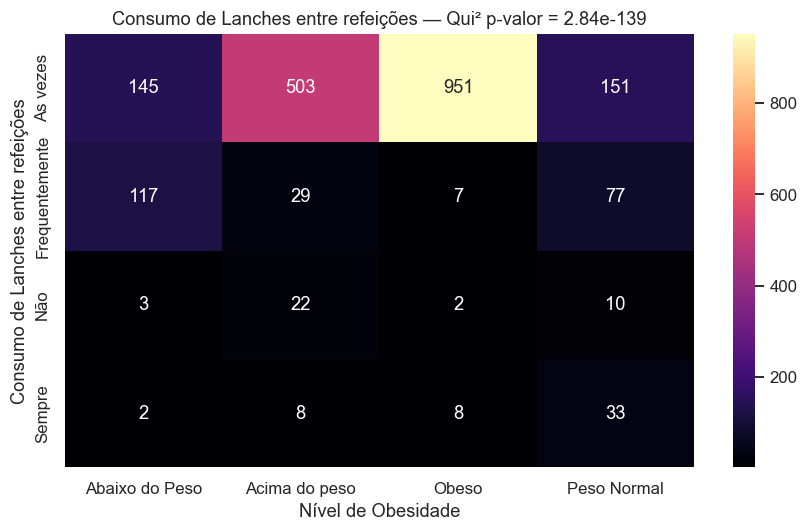

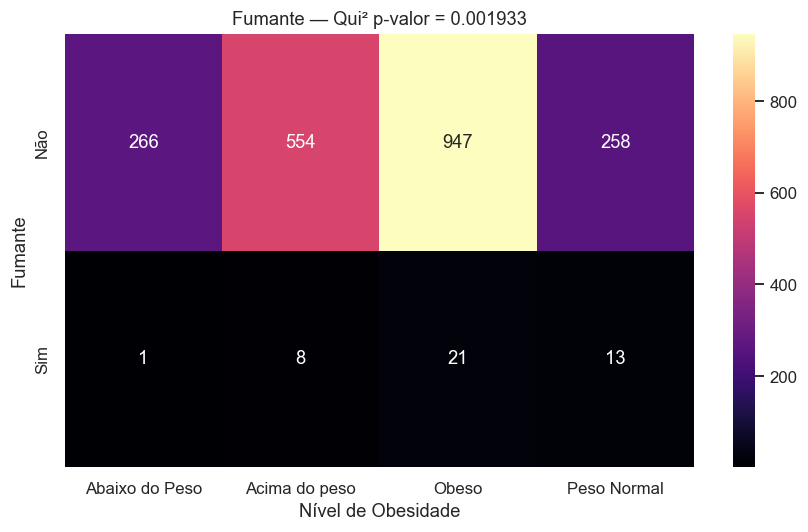

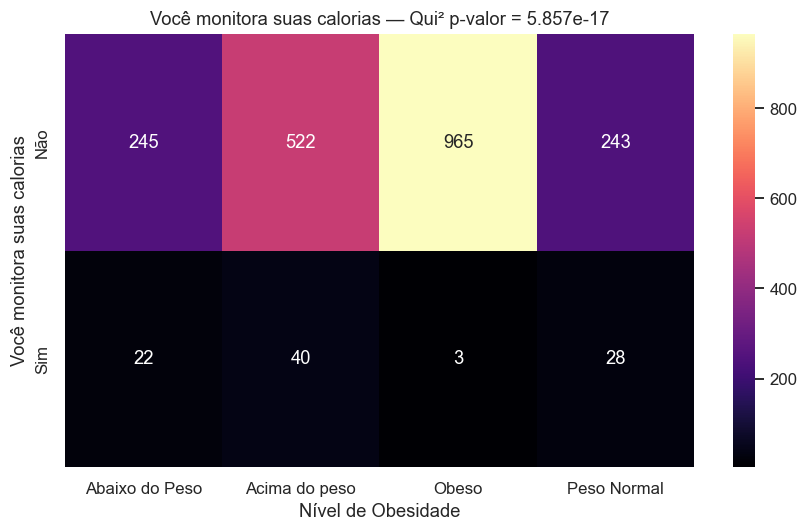

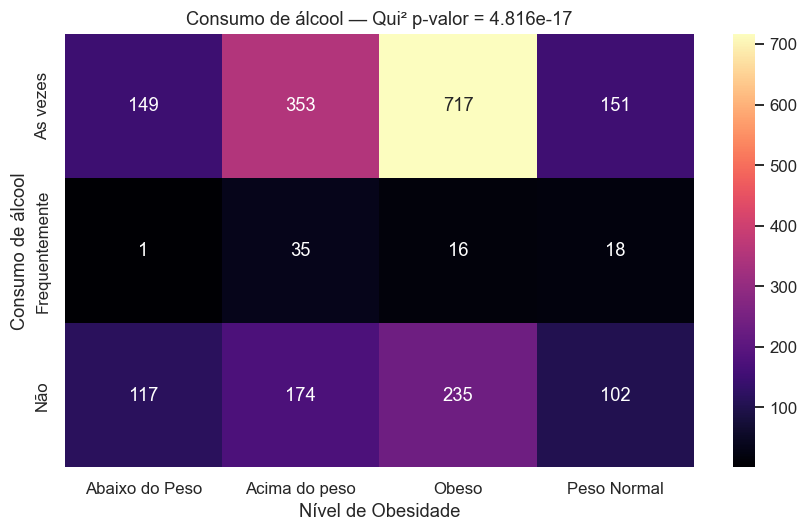

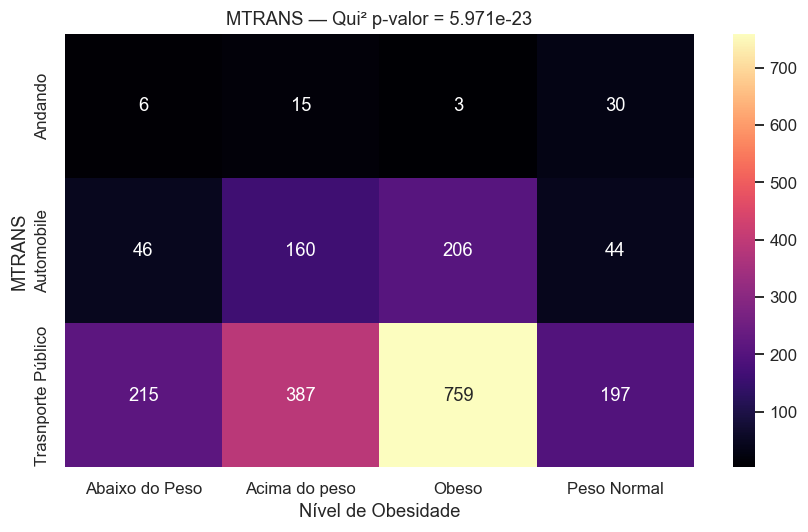

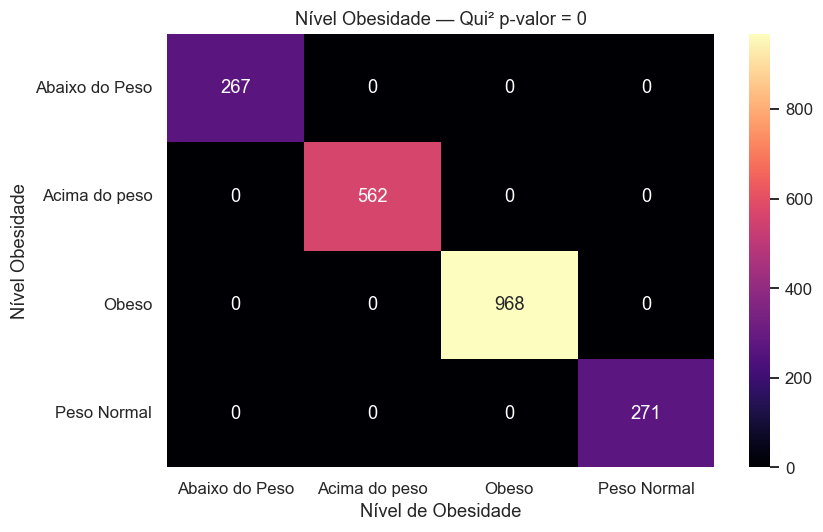

In [25]:
"""### Teste Qui-Quadrado — Variáveis Qualitativas"""

resultados_chi2 = []

for variavel in VARS_QUALI:

    # Tabela de contingência
    contingencia = pd.crosstab(
        df[variavel],
        df["Nível Obesidade"]
    )

    # Teste Qui-Quadrado
    chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

    # Armazena os resultados
    resultados_chi2.append({
        "Variável": variavel,
        "Qui²": chi2,
        "P-valor": p_chi2,
        "Graus de liberdade": gl,
        "Frequências esperadas < 5": (esperado < 5).sum()
    })

    # Mapa de calor
    fig, ax = plt.subplots(figsize=(8, 5))

    sns.heatmap(
        contingencia,
        annot=True,
        fmt="d",
        cmap="magma",
        ax=ax
    )

    ax.set_title(f"{variavel} — Qui² p-valor = {p_chi2:.4g}")
    ax.set_xlabel("Nível de Obesidade")
    ax.set_ylabel(variavel)

    plt.tight_layout()
    plt.show()

# Tabela consolidada
resultados_chi2 = pd.DataFrame(resultados_chi2)


O Maior insight retirado do Chi Quadrado é que a categora de "Fumantes" aparenta ser a menos associada com o nível de Obesidade

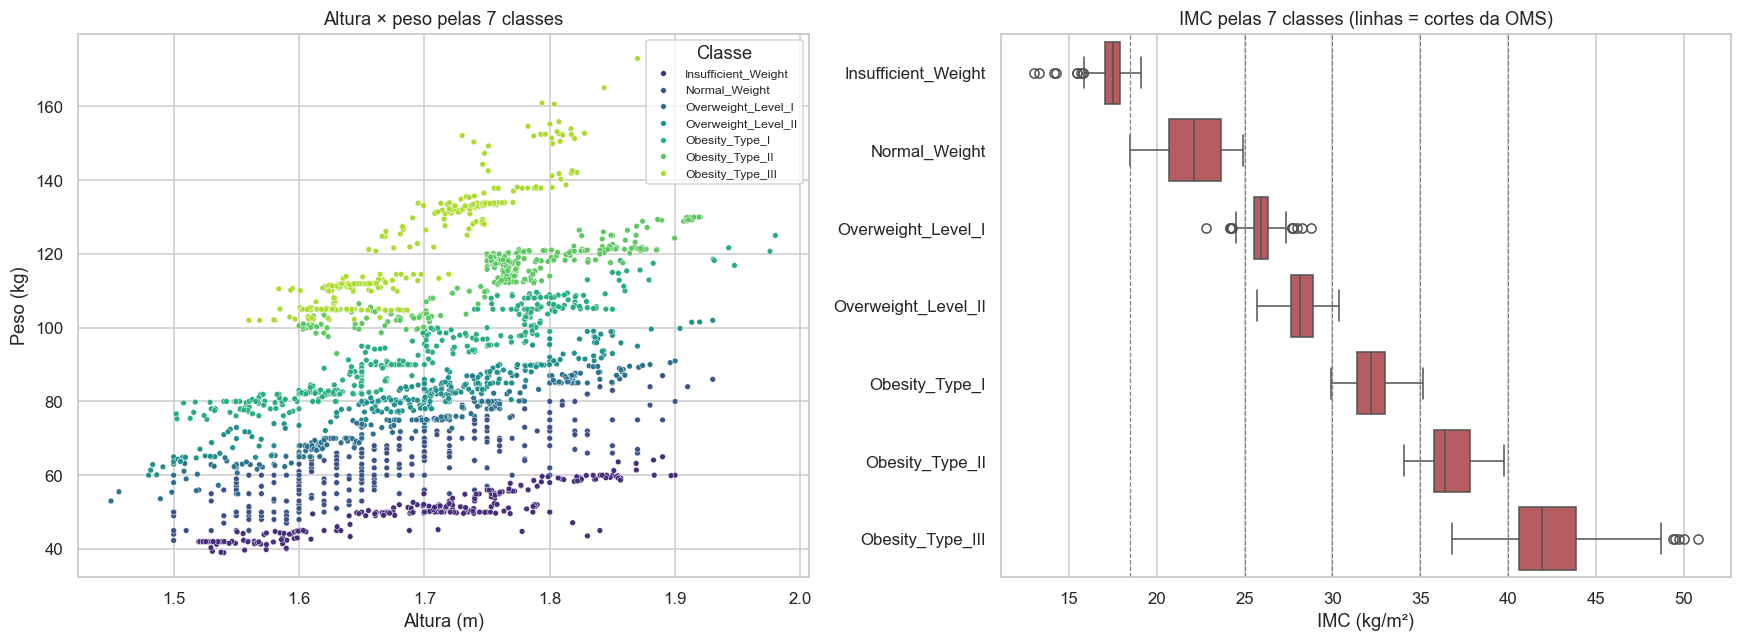

,min,median,max
NObeyesdad,,,
Insufficient_Weight,13.0,17.5,19.1
Normal_Weight,18.5,22.1,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.1,30.4
Obesity_Type_I,29.9,32.2,35.2
Obesity_Type_II,34.0,36.4,39.8
Obesity_Type_III,36.8,41.9,50.8


In [26]:
# [IA] Claude: altura × peso e IMC pelas 7 classes originais (base usada no K-Means)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=df_K, x="Height", y="Weight", hue=ALVO, hue_order=ORDEM_CLASSES,
                palette="viridis", s=14, ax=axes[0])
axes[0].set(title="Altura × peso pelas 7 classes", xlabel="Altura (m)", ylabel="Peso (kg)")
axes[0].legend(title="Classe", fontsize=8)
sns.boxplot(data=df_K, y=ALVO, x="IMC", order=ORDEM_CLASSES, ax=axes[1], color="#C44E52")
for lim in [18.5, 25, 30, 35, 40]:
    axes[1].axvline(lim, ls="--", c="gray", lw=0.8)
axes[1].set(title="IMC pelas 7 classes (linhas = cortes da OMS)", xlabel="IMC (kg/m²)", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "C5_altura_peso_imc.png"); plt.show()

imc_classe = df_K.groupby(ALVO)["IMC"].agg(["min", "median", "max"]).reindex(ORDEM_CLASSES).round(1)
imc_classe.to_csv(OUT / "imc_por_classe.csv")
imc_classe

**O que as relações mostram**
- **Weight** é a variável mais associada ao IMC (ρ ≈ 0,93). Age tem associação moderada (ρ ≈ 0,40) e Height, fraca (ρ ≈ 0,12). Os hábitos (FCVC, FAF, CH2O, TUE) têm correlações baixas, abaixo de 0,3 em módulo, entre si e com o IMC.
- No gráfico altura × peso, as classes formam **faixas diagonais**, as curvas de IMC constante. As faixas vizinhas **se tocam e se sobrepõem**.
- No boxplot do IMC, as classes seguem a ordem esperada, mas há **sobreposição entre classes vizinhas**. Overweight_Level_I e Overweight_Level_II, por exemplo, dividem a faixa de 25,7 a 28,8, e Obesity_Type_II e Obesity_Type_III dividem a faixa de 36,8 a 39,8. Os registros sintéticos interpolados entre classes vizinhas são a explicação provável.
- Histórico familiar e FAVC crescem nas classes de obesidade. **Obesity_Type_II é quase só masculina e Obesity_Type_III quase só feminina**, um viés da amostra.

## 4. EDA, pilar 4: outliers

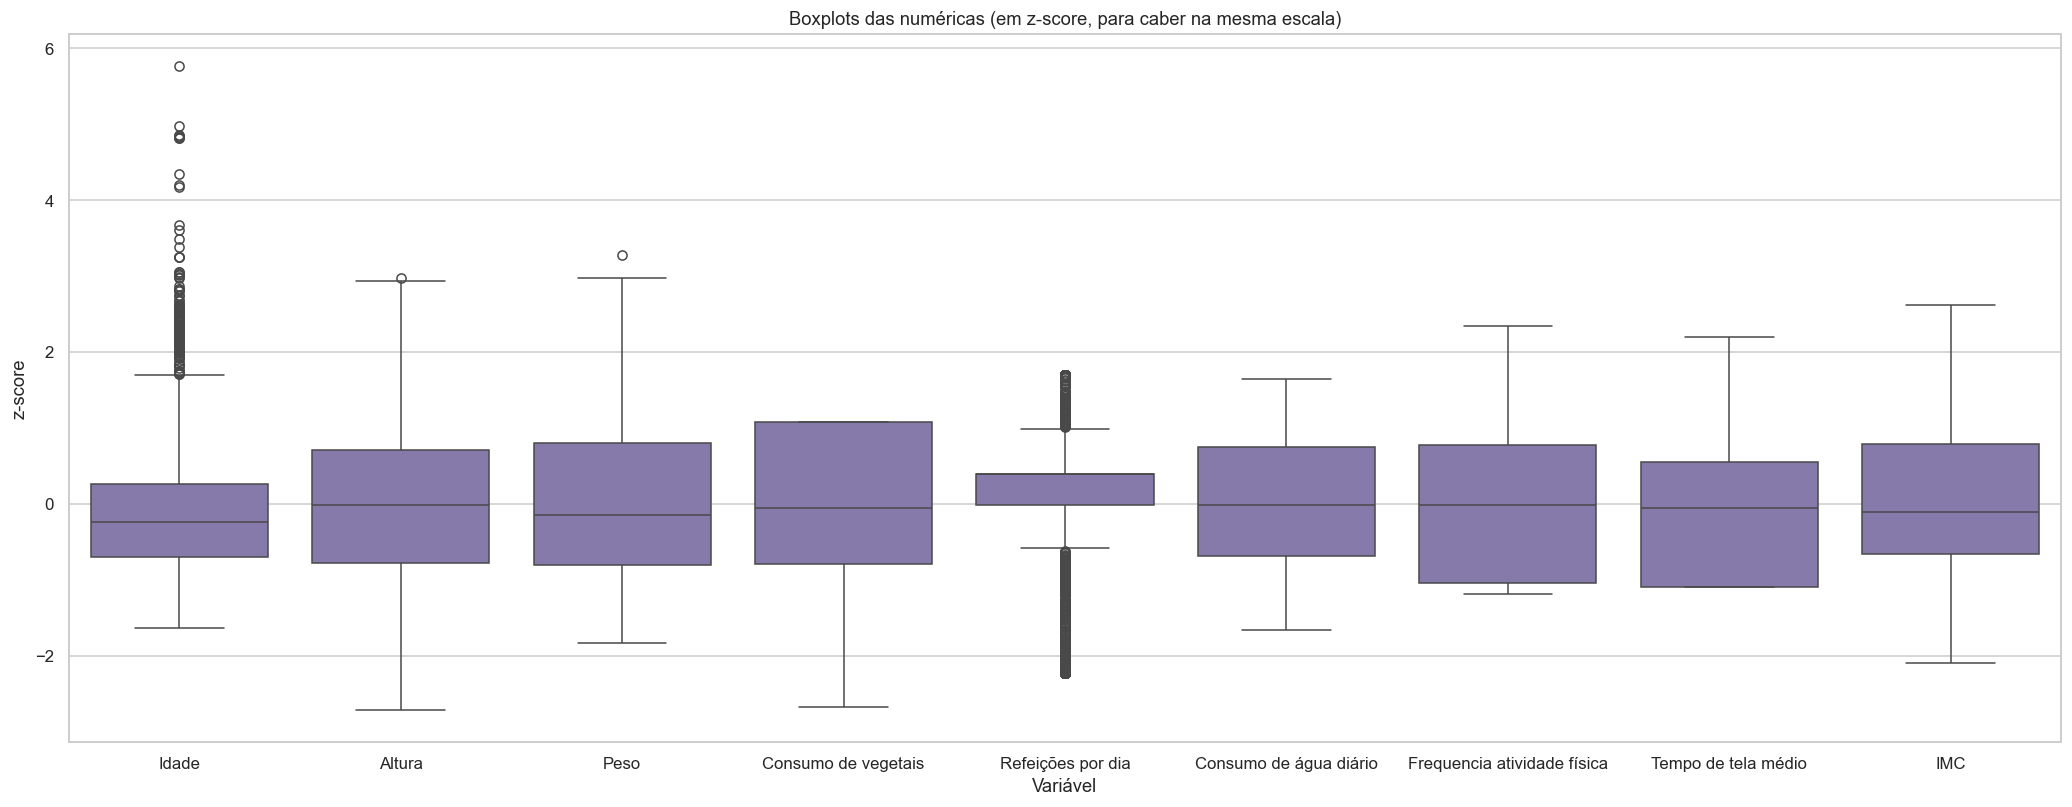

,n_outliers,min,max,%
Idade,164,14.000000,61.000000,7.93
Altura,1,1.450000,1.980000,0.05
Peso,1,39.000000,173.000000,0.05
Consumo de vegetais,0,1.000000,3.000000,0.00
Refeições por dia,573,1.000000,4.000000,27.71
Consumo de água diário,0,1.000000,3.000000,0.00
Frequencia atividade física,0,0.000000,3.000000,0.00
Tempo de tela médio,0,0.000000,2.000000,0.00
IMC,0,12.998685,50.811753,0.00


In [27]:
# [IA] Claude: triagem de outliers pelo critério IQR (1,5 × IQR)
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out_tab = pd.DataFrame({
    "n_outliers": {c: outliers_iqr(df[c]) for c in VARS_QUANT},
    "min": df[VARS_QUANT].min(), "max": df[VARS_QUANT].max(),
})
out_tab["%"] = (out_tab.n_outliers / len(df) * 100).round(2)
out_tab.to_csv(OUT / "outliers_iqr.csv")

fig, ax = plt.subplots(figsize=(19, 7.5))
z = (df[VARS_QUANT] - df[VARS_QUANT].mean()) / df[VARS_QUANT].std()
sns.boxplot(data=z, ax=ax, color="#8172B2")
ax.set(title="Boxplots das numéricas (em z-score, para caber na mesma escala)",
       xlabel="Variável", ylabel="z-score")
plt.tight_layout(); plt.savefig(FIG / "C7_outliers.png"); plt.show()
out_tab

**Decisão sobre outliers**
- Os outliers do IQR se concentram em **Age**, com idades acima de cerca de 35 anos numa amostra jovem, e em **NCP**, que fica quase sempre em 3, então qualquer outro valor vira "outlier". Peso e altura têm pouquíssimos.
- Todos os valores são **plausíveis**: não existe idade de 200 nem altura de 3 m. Eles não são erro de digitação, e sim pessoas reais menos frequentes.
- **Decisão: manter.** Removê-los apagaria grupos reais, como as pessoas mais velhas. O K-Means é sensível a extremos, mas a padronização reduz o peso de cada um, e a fração de outliers é pequena.

## 5. Pré-processamento e padronização

**Codificação**
- Binárias (Gender, family_history, FAVC, SMOKE e SCC) viram 0 ou 1.
- Ordinais (CAEC e CALC) viram no = 0, Sometimes = 1, Frequently = 2 e Always = 3.
- MTRANS, que é nominal, passa por one-hot: uma coluna 0/1 por meio de transporte.
- O alvo **NObeyesdad sai** da matriz de atributos e o IMC não entra, porque o K-Means é não supervisionado. O rótulo só volta depois, para avaliar os clusters.

**Por que o K-Means precisa de padronização.** O K-Means agrupa os pontos pela **distância euclidiana** até os centróides. Quando as variáveis estão em escalas diferentes, a variável com maior amplitude domina a distância. Aqui, o desvio-padrão do peso (≈ 26 kg) é cerca de 280 vezes o da altura (≈ 0,09 m). Sem padronizar, o algoritmo agruparia praticamente só pelo peso, e altura, hábitos e idade não fariam diferença. O `StandardScaler` transforma cada coluna em z = (x − média) / desvio-padrão, com média 0 e desvio 1, e assim todas as variáveis passam a contribuir na mesma escala.

In [28]:
# [IA] Claude: codificação

X = df_K.drop(columns=[ALVO, "IMC"]).copy()
for c in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    X[c] = (X[c] == "yes").astype(int)
X["Gender"] = (X["Gender"] == "Male").astype(int)
ORD = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
X["CAEC"] = X["CAEC"].map(ORD)
X["CALC"] = X["CALC"].map(ORD)
X = pd.get_dummies(X, columns=["MTRANS"], dtype=int)
y = df_K[ALVO]
print(X.shape)

# [IA] Claude: padronização
scaler = StandardScaler()
Z = scaler.fit_transform(X)

antes_depois = pd.DataFrame({
    "desvio_antes": X.std(), "desvio_depois": pd.DataFrame(Z, columns=X.columns).std()
}).round(3)
antes_depois

(2068, 18)


,desvio_antes,desvio_depois
Gender,0.500,1.0
Age,6.357,1.0
Height,0.093,1.0
Weight,26.241,1.0
family_history_with_overweight,0.378,1.0
FAVC,0.318,1.0
FCVC,0.533,1.0
NCP,0.764,1.0
CAEC,0.456,1.0
SMOKE,0.143,1.0


## 6. Funções de avaliação

Os clusters do K-Means não têm nome, apenas números de 0 a k−1. Para comparar com as classes reais:
1. **Mapeamento:** cada cluster recebe a **classe majoritária** entre os seus membros.
2. Todo ponto passa a ter uma "classe prevista", a classe do seu cluster.
3. Com a classe prevista, calculamos a matriz de confusão (real × prevista), a acurácia e a precisão e o recall de cada classe.

Quando k < 7, ou quando dois clusters têm a mesma classe majoritária, algumas classes **nunca são previstas**. Nesse caso a precisão delas é indefinida (registrada como 0) e o recall é 0.

In [29]:
# [IA] Claude: funções reutilizadas nas duas passadas
def mapear_clusters(rotulos, y):
    tab = pd.crosstab(pd.Series(rotulos, name="cluster"), y)
    return tab, tab.idxmax(axis=1)

def avaliar(k, Z, y, nome):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    tab, mapa = mapear_clusters(km.labels_, y)
    y_pred = pd.Series(km.labels_, index=y.index).map(mapa)

    metr = pd.DataFrame({
        "precisao": precision_score(y, y_pred, labels=ORDEM_CLASSES, average=None, zero_division=0),
        "recall": recall_score(y, y_pred, labels=ORDEM_CLASSES, average=None, zero_division=0),
        "suporte": y.value_counts().reindex(ORDEM_CLASSES).values,
        "prevista_por_algum_cluster": [c in set(mapa) for c in ORDEM_CLASSES],
    }, index=ORDEM_CLASSES).round(3)
    acc = accuracy_score(y, y_pred)

    # composição dos clusters
    tab_out = tab.reindex(columns=ORDEM_CLASSES)
    tab_out["classe_majoritaria"] = mapa
    tab_out["pureza"] = (tab.max(axis=1) / tab.sum(axis=1)).round(3)
    tab_out.to_csv(OUT / f"{nome}_composicao_clusters.csv")
    metr.to_csv(OUT / f"{nome}_metricas.csv")

    # matriz de confusão
    cm = confusion_matrix(y, y_pred, labels=ORDEM_CLASSES)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    curtos = ["Insuf.", "Normal", "Sobrep. I", "Sobrep. II", "Obes. I", "Obes. II", "Obes. III"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=curtos, yticklabels=curtos,
                ax=ax, cbar_kws={"label": "Nº de registros"})
    ax.set(title=f"Matriz de confusão: {nome} (k = {k}), acurácia = {acc:.1%}",
           xlabel="Classe prevista (majoritária do cluster)", ylabel="Classe real")
    plt.tight_layout(); plt.savefig(FIG / f"{nome}_matriz_confusao.png"); plt.show()

    print(f"Acurácia ({nome}, k={k}): {acc:.3f}")
    print("Mapeamento cluster → classe:", mapa.to_dict())
    return {"km": km, "acc": acc, "metricas": metr, "composicao": tab_out, "mapa": mapa}

## 7. K-Means, passada 1: k livre (2 a 10) pelo Método do Cotovelo

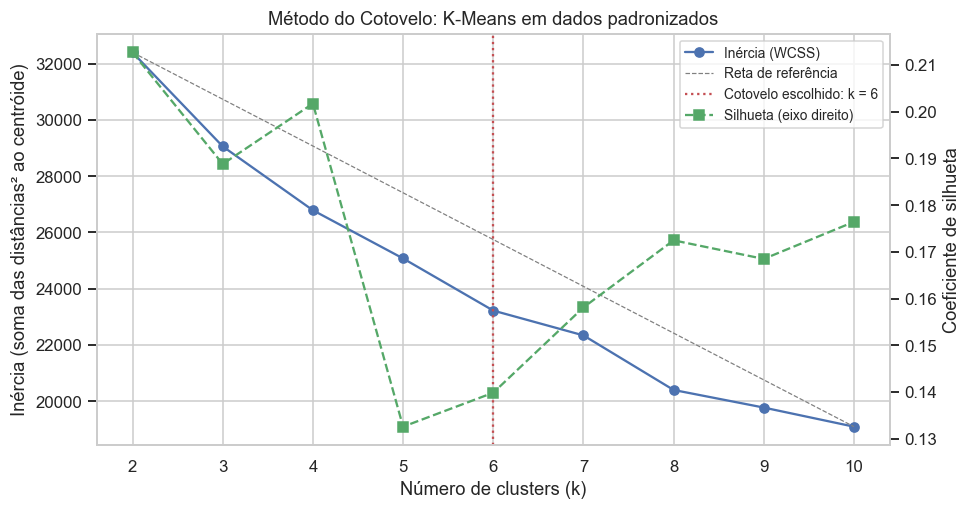

k escolhido pelo cotovelo: 6


,k,inercia,queda_vs_k_anterior,distancia_a_reta,silhueta
0,2,32396.6,NaN,0.000,0.213
1,3,29057.8,3338.8,0.126,0.189
2,4,26789.3,2268.5,0.172,0.202
3,5,25076.7,1712.6,0.175,0.133
4,6,23223.9,1852.8,0.190,0.140
5,7,22342.4,881.5,0.131,0.158
6,8,20403.2,1939.2,0.152,0.172
7,9,19777.5,625.7,0.074,0.168
8,10,19098.9,678.6,0.000,0.176


In [30]:
# [IA] Claude: inércia (WCSS) para k = 2..10 e silhueta como critério auxiliar
ks = list(range(2, 11))
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(Z, km.labels_))

# Cotovelo objetivo: ponto da curva mais distante da reta que liga k=2 a k=10
xn = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
yn = (np.array(inercias) - min(inercias)) / (max(inercias) - min(inercias))
distancia = (1 - xn) - yn
K_COTOVELO = ks[int(np.argmax(distancia))]

cotovelo = pd.DataFrame({"k": ks, "inercia": np.round(inercias, 1),
                         "queda_vs_k_anterior": np.r_[np.nan, -np.diff(inercias)].round(1),
                         "distancia_a_reta": distancia.round(3),
                         "silhueta": np.round(silhuetas, 3)})
cotovelo.to_csv(OUT / "cotovelo.csv", index=False)

fig, ax1 = plt.subplots(figsize=(9, 4.8))
ax1.plot(ks, inercias, "o-", c="#4C72B0", label="Inércia (WCSS)")
ax1.plot([ks[0], ks[-1]], [inercias[0], inercias[-1]], "--", c="gray", lw=0.8, label="Reta de referência")
ax1.axvline(K_COTOVELO, c="#C44E52", ls=":", label=f"Cotovelo escolhido: k = {K_COTOVELO}")
ax1.set(xlabel="Número de clusters (k)", ylabel="Inércia (soma das distâncias² ao centróide)",
        title="Método do Cotovelo: K-Means em dados padronizados")
ax2 = ax1.twinx()
ax2.plot(ks, silhuetas, "s--", c="#55A868", label="Silhueta (eixo direito)")
ax2.set_ylabel("Coeficiente de silhueta"); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "C8_cotovelo.png"); plt.show()
print("k escolhido pelo cotovelo:", K_COTOVELO)
cotovelo

**Leitura do cotovelo.** A inércia cai de forma quase linear, sem uma "dobra" nítida. Para não depender só do olho, usamos o critério da **maior distância até a reta** que liga k=2 a k=10. A distância é máxima em **k = 6** (0,190), mas fica muito perto em k = 5 (0,175) e k = 4 (0,172). Esse cotovelo fraco já indica que os dados **não têm grupos naturais bem separados**. A silhueta, sempre abaixo de 0,22, confirma que os clusters são pouco compactos.

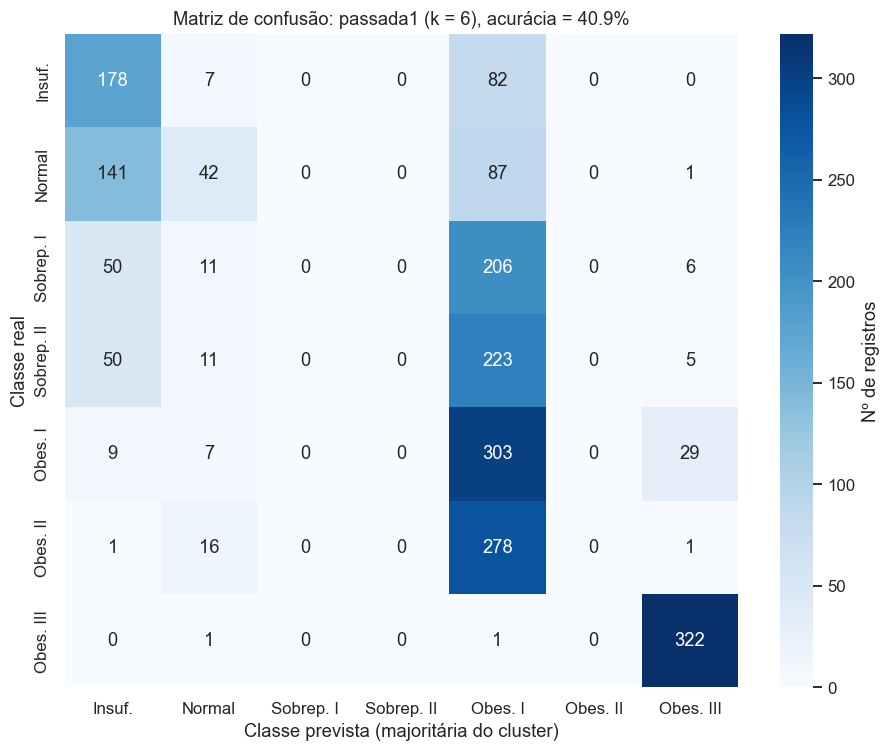

Acurácia (passada1, k=6): 0.409
Mapeamento cluster → classe: {0: 'Obesity_Type_III', 1: 'Obesity_Type_I', 2: 'Obesity_Type_I', 3: 'Insufficient_Weight', 4: 'Normal_Weight', 5: 'Normal_Weight'}


NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_majoritaria,pureza
cluster,,,,,,,,,
0,0,12,6,11,23,19,293,Obesity_Type_III,0.805
1,55,39,62,83,104,85,0,Obesity_Type_I,0.243
2,52,58,131,133,193,174,1,Obesity_Type_I,0.260
3,155,116,61,54,17,8,11,Insufficient_Weight,0.367
4,0,16,4,3,8,10,0,Normal_Weight,0.390
5,5,30,9,5,3,0,0,Normal_Weight,0.577


In [31]:
# [IA] Claude: passada 1 com o k do cotovelo
p1 = avaliar(K_COTOVELO, Z, y, "passada1")
p1["composicao"]

In [32]:
p1["metricas"]

,precisao,recall,suporte,prevista_por_algum_cluster
Insufficient_Weight,0.415,0.667,267,True
Normal_Weight,0.442,0.155,271,True
Overweight_Level_I,0.000,0.000,273,False
Overweight_Level_II,0.000,0.000,289,False
Obesity_Type_I,0.257,0.871,348,True
Obesity_Type_II,0.000,0.000,296,False
Obesity_Type_III,0.885,0.994,324,True


## 8. K-Means, passada 2: k = 7, o número real de classes

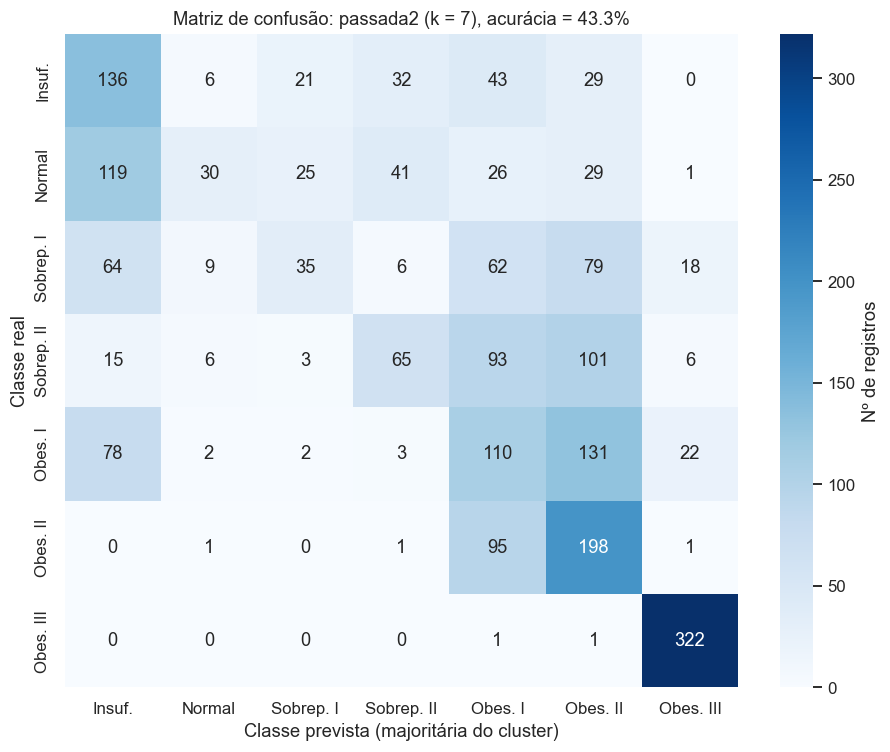

Acurácia (passada2, k=7): 0.433
Mapeamento cluster → classe: {0: 'Overweight_Level_I', 1: 'Insufficient_Weight', 2: 'Obesity_Type_II', 3: 'Obesity_Type_I', 4: 'Overweight_Level_II', 5: 'Obesity_Type_III', 6: 'Normal_Weight'}


NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,classe_majoritaria,pureza
cluster,,,,,,,,,
0,17,22,29,7,4,2,3,Overweight_Level_I,0.345
1,129,92,64,30,79,6,7,Insufficient_Weight,0.317
2,33,35,82,98,135,183,0,Obesity_Type_II,0.323
3,54,35,63,82,107,85,0,Obesity_Type_I,0.251
4,29,46,8,55,2,1,2,Overweight_Level_II,0.385
5,0,11,18,12,17,19,293,Obesity_Type_III,0.792
6,5,30,9,5,4,0,0,Normal_Weight,0.566


In [33]:
# [IA] Claude: passada 2 com k igual ao número de classes
K_REAL = y.nunique()
p2 = avaliar(K_REAL, Z, y, "passada2")
p2["composicao"]

In [34]:
p2["metricas"]

,precisao,recall,suporte,prevista_por_algum_cluster
Insufficient_Weight,0.330,0.509,267,True
Normal_Weight,0.556,0.111,271,True
Overweight_Level_I,0.407,0.128,273,True
Overweight_Level_II,0.439,0.225,289,True
Obesity_Type_I,0.256,0.316,348,True
Obesity_Type_II,0.349,0.669,296,True
Obesity_Type_III,0.870,0.994,324,True


## 9. Comparação das duas passadas

In [35]:
# [IA] Claude: tabela comparativa
comp = pd.DataFrame({
    "Passada 1 (cotovelo)": {
        "k": K_COTOVELO, "acurácia": round(p1["acc"], 3),
        "classes nunca previstas": int((~p1["metricas"].prevista_por_algum_cluster).sum()),
        "recall médio (macro)": round(p1["metricas"].recall.mean(), 3),
        "pureza média dos clusters": round(p1["composicao"].pureza.mean(), 3),
        "silhueta": round(silhouette_score(Z, p1["km"].labels_), 3)},
    "Passada 2 (k = 7)": {
        "k": K_REAL, "acurácia": round(p2["acc"], 3),
        "classes nunca previstas": int((~p2["metricas"].prevista_por_algum_cluster).sum()),
        "recall médio (macro)": round(p2["metricas"].recall.mean(), 3),
        "pureza média dos clusters": round(p2["composicao"].pureza.mean(), 3),
        "silhueta": round(silhouette_score(Z, p2["km"].labels_), 3)},
})
comp.to_csv(OUT / "comparacao_passadas.csv")
comp

,Passada 1 (cotovelo),Passada 2 (k = 7)
k,6.000,7.000
acurácia,0.409,0.433
classes nunca previstas,3.000,0.000
recall médio (macro),0.384,0.422
pureza média dos clusters,0.440,0.426
silhueta,0.140,0.158


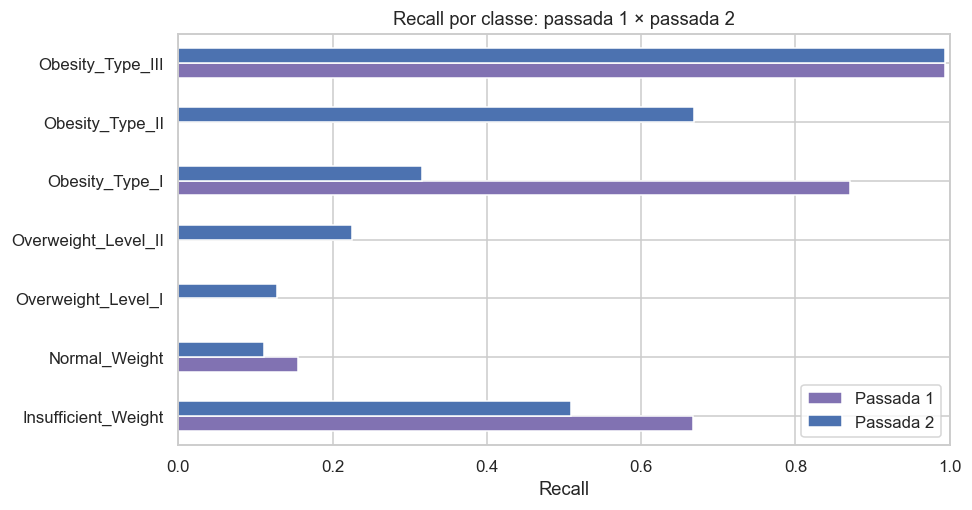

In [36]:
# [IA] Claude: recall por classe nas duas passadas
rc = pd.DataFrame({"Passada 1": p1["metricas"].recall, "Passada 2": p2["metricas"].recall})
ax = rc.plot(kind="barh", figsize=(9, 4.8), color=["#8172B2", "#4C72B0"])
ax.set(title="Recall por classe: passada 1 × passada 2", xlabel="Recall", ylabel="", xlim=(0, 1))
plt.tight_layout(); plt.savefig(FIG / "C9_recall_passadas.png"); plt.show()

### Visualização dos clusters (PCA em 2 dimensões)

Os dados têm 18 dimensões. Para enxergar os clusters, projetamos os dados padronizados nos **2 primeiros componentes principais (PCA)**. A projeção serve só para visualizar, porque o K-Means rodou nas 18 dimensões. Os três painéis usam os mesmos pontos:
- à esquerda, coloridos pela **classe real**;
- no meio, pelos **clusters da passada 1**;
- à direita, pelos **clusters da passada 2**.

Os X marcam os centróides projetados.

Variância explicada: PC1 = 15.5%, PC2 = 12.9%, total = 28.4%


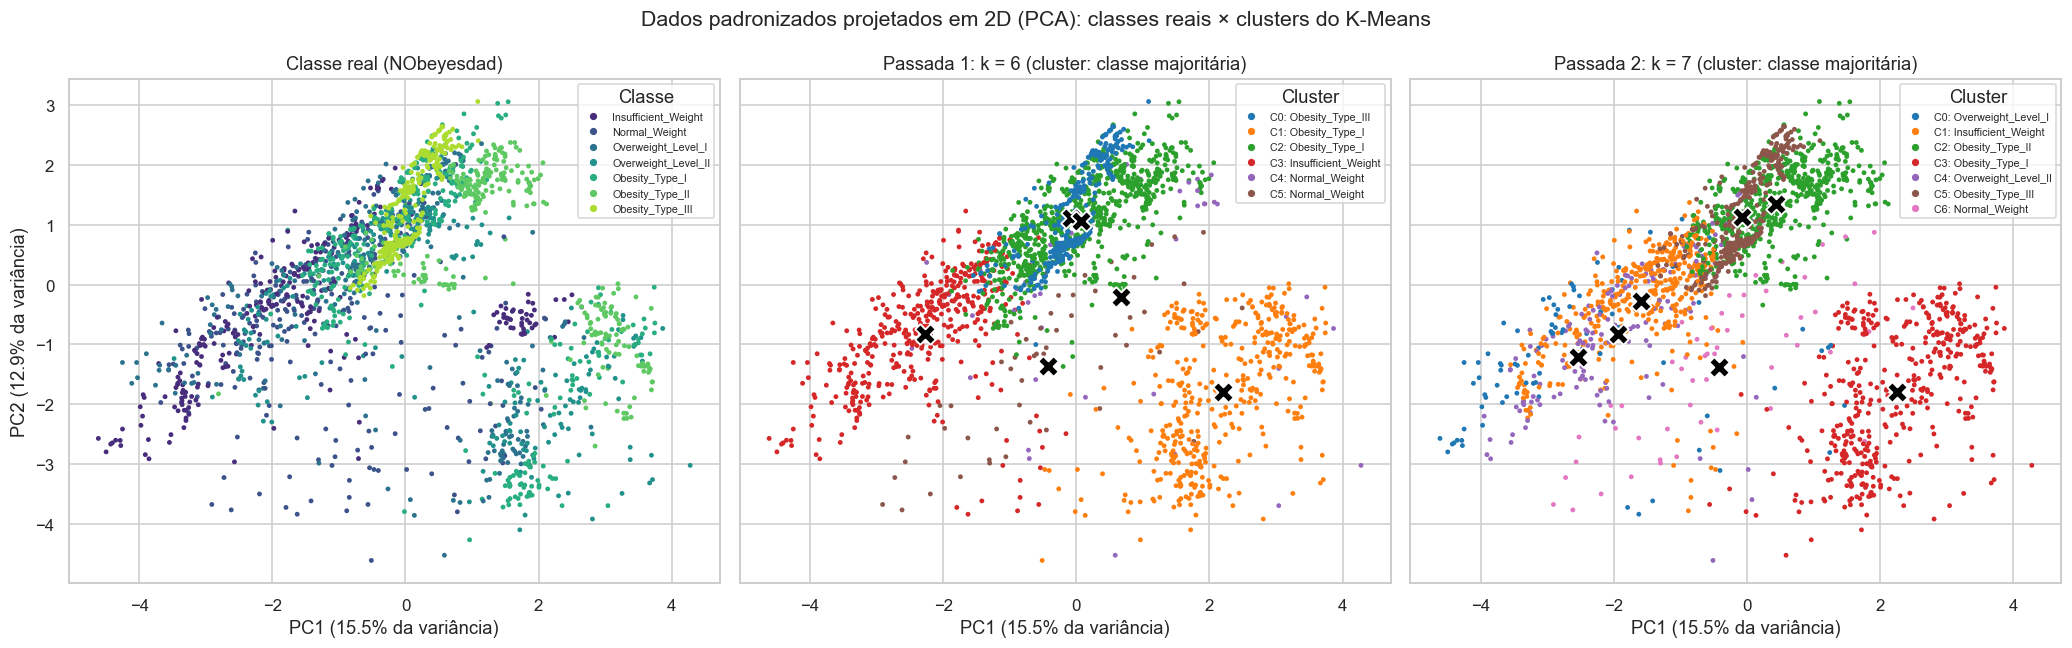

In [37]:
# [IA] Claude: projeção PCA 2D, classes reais × clusters das duas passadas
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=SEED)
P2 = pca.fit_transform(Z)
var = pca.explained_variance_ratio_ * 100
print(f"Variância explicada: PC1 = {var[0]:.1f}%, PC2 = {var[1]:.1f}%, total = {var.sum():.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharex=True, sharey=True)
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=y, hue_order=ORDEM_CLASSES, palette="viridis",
                s=10, ax=axes[0], linewidth=0)
axes[0].set_title("Classe real (NObeyesdad)")
axes[0].legend(title="Classe", fontsize=7, markerscale=1.5)
for ax, res, nome in [(axes[1], p1, f"Passada 1: k = {K_COTOVELO}"), (axes[2], p2, f"Passada 2: k = {K_REAL}")]:
    lab = res["km"].labels_
    rot = [f"C{c}: {res['mapa'][c]}" for c in lab]
    ordem = [f"C{c}: {res['mapa'][c]}" for c in sorted(set(lab))]
    sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=rot, hue_order=ordem, palette="tab10",
                    s=10, ax=ax, linewidth=0)
    cent = pca.transform(res["km"].cluster_centers_)
    ax.scatter(cent[:, 0], cent[:, 1], marker="X", s=180, c="black", edgecolor="white", linewidth=1.2)
    ax.set_title(f"{nome} (cluster: classe majoritária)")
    ax.legend(title="Cluster", fontsize=7, markerscale=1.5)
for ax in axes:
    ax.set(xlabel=f"PC1 ({var[0]:.1f}% da variância)", ylabel=f"PC2 ({var[1]:.1f}% da variância)")
fig.suptitle("Dados padronizados projetados em 2D (PCA): classes reais × clusters do K-Means", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "C10_clusters_pca.png"); plt.show()

**Leitura.**
- **O plano tem duas massas principais, e elas não correspondem às classes.** A faixa diagonal de cima reúne quem usa transporte público. A nuvem de baixo, à direita, reúne quem usa automóvel, pessoas mais velhas, com média de 32 anos. O K-Means captura essa divisão: o cluster C1 da passada 1 e o C3 da passada 2 são a nuvem do automóvel, e por isso misturam todas as classes de peso.
- **Dentro de cada massa, as classes reais formam um gradiente ordenado,** de Insufficient_Weight a Obesity_Type_III ao longo da diagonal. Não há fronteiras: cada classe encosta na vizinha. É a imagem de um contínuo (IMC), não de grupos separados.
- **Alguns clusters são pequenos e espalhados no centro,** porque são definidos por um hábito raro, e não pelo peso. Na passada 1, são os fumantes (C4) e quem anda a pé (C5). Na passada 2, são quem monitora calorias (C0), quem não come alimentos calóricos (C4) e quem anda a pé (C6).
- Os dois componentes explicam só 28,4% da variância (15,5% + 12,9%), então parte da sobreposição vem da projeção. A baixa pureza dos clusters, medida nas 18 dimensões, confirma que a mistura também é real.

## 10. Análise complementar: e se o K-Means visse só o que define a classe?

Como o rótulo é uma faixa de IMC, testamos o K-Means com k = 7 em dois conjuntos menores, padronizados da mesma forma:
- (a) só **altura e peso**;
- (b) só o **IMC**.

O teste não substitui as passadas exigidas. Ele serve para entender **por que** as passadas 1 e 2 têm desempenho baixo.

In [38]:
# [IA] Claude: K-Means k=7 com subconjuntos de atributos
Z_hw = StandardScaler().fit_transform(df_K[["Height", "Weight"]])
Z_imc = StandardScaler().fit_transform(df_K[["IMC"]])
Z_habitos = StandardScaler().fit_transform(X.drop(columns=["Height", "Weight"]))
comp_ext = {}
for nome, Zs in [("todos_atributos", Z), ("sem_altura_peso", Z_habitos),
                 ("altura_peso", Z_hw), ("so_imc", Z_imc)]:
    lab = KMeans(n_clusters=7, n_init=10, random_state=SEED).fit_predict(Zs)
    _, mapa = mapear_clusters(lab, y)
    pred = pd.Series(lab, index=y.index).map(mapa)
    comp_ext[nome] = {"acurácia": round(accuracy_score(y, pred), 3),
                      "classes nunca previstas": 7 - mapa.nunique()}
comp_ext = pd.DataFrame(comp_ext).T
comp_ext.to_csv(OUT / "analise_complementar_atributos.csv")
comp_ext

,acurácia,classes nunca previstas
todos_atributos,0.433,0.0
sem_altura_peso,0.408,2.0
altura_peso,0.446,0.0
so_imc,0.793,1.0


## 11. Discussão crítica

> Texto redigido com apoio de IA (Claude) a partir dos resultados acima. O grupo revisou e se responsabiliza. Ver `docs/DECLARACAO_IA.pdf`.

**1. Comparação das passadas.**
- A **passada 1** (k = 6) tem acurácia de 40,9%. **3 das 7 classes nunca são previstas** (Overweight I, Overweight II e Obesity II) e ficam com recall zero.
- A **passada 2** (k = 7) chega a 43,3% e todas as classes passam a ser previstas por algum cluster, mas com recall muito baixo nas faixas do meio: Normal_Weight (11,1%), Overweight_Level_I (12,8%) e Overweight_Level_II (22,5%).
- Só **Obesity_Type_III** é bem recuperada nas duas passadas (recall de 99,4%), porque essa classe é 99,7% feminina e muito pesada: o K-Means forma um cluster de "mulheres com peso alto" que coincide com ela.
- A melhora entre as passadas é pequena: a pureza média quase não muda (0,440 e 0,426) e a silhueta segue baixa (0,140 e 0,158).

**2. O que os clusters realmente separam.** Os perfis médios dos clusters mostram o motivo.
- Na EDA, o grupo já tinha removido as categorias mais raras (bicicleta, moto e álcool "Sempre", 19 registros), porque desbalanceavam a análise. Mesmo assim, o K-Means continua formando clusters em torno de **outros atributos binários raros**:
  - na passada 1, um cluster só de **fumantes** (42 dos 43) e um só de **quem anda a pé** (53);
  - na passada 2, um cluster de **quem monitora calorias** (86 dos 93), um de **quem não come alimentos calóricos** (148) e um de **quem anda a pé** (54).
- Isso é um efeito da padronização sobre variáveis binárias raras. SMOKE vale 1 em só 2% das linhas. Padronizado, esse 1 vira z ≈ 6,9 e pesa muito na distância euclidiana. Para o K-Means, "fumar" afasta mais duas pessoas do que vários quilos de diferença.
- Os outros clusters seguem **meio de transporte, sexo e idade**: automóvel (mais velhos, 32 anos em média), homens pesados e mulheres pesadas. É a estrutura dominante no conjunto dos 18 atributos, e não a estrutura do IMC.

**3. As classes originais fazem sentido?** Por exemplo, Sobrepeso e Obesidade I são mesmo diferentes?
- Do ponto de vista **clínico**, sim. São faixas de IMC da OMS (25 a 29,9 e 30 a 34,9) com riscos de saúde diferentes.
- Do ponto de vista **dos dados**, não como grupos naturais. São cortes arbitrários num **contínuo**. Uma pessoa com IMC 29,8 e outra com 30,1 são quase idênticas em todos os atributos, mas ficam em classes diferentes. Não existe uma "lacuna" de densidade entre as faixas que o K-Means possa encontrar.
- Neste dataset, a fronteira é ainda mais borrada. O boxplot do IMC mostra **sobreposição entre classes vizinhas** (Overweight I e II dividem a faixa de 25,7 a 28,8; Obesity II e III, a de 36,8 a 39,8), provavelmente por causa dos 77% de registros sintéticos gerados por SMOTE, que interpola pontos entre vizinhos.
- Por isso Sobrepeso I e II **não têm cluster próprio na passada 1** e, na passada 2, só aparecem como classe majoritária de clusters definidos por hábitos (monitorar calorias e não comer alimentos calóricos), com recall abaixo de 23%. Elas ficam "espremidas" entre Normal e Obesidade I.
- Na prática, os dados sustentam no máximo 3 ou 4 grupos amplos. É a mesma ideia do agrupamento que o grupo usou na EDA, com 4 níveis: abaixo do peso, peso normal, acima do peso e obeso.

**4. A análise complementar confirma.** Os resultados com k = 7 e conjuntos diferentes de atributos:
- só altura e peso: acurácia de **44,6%**;
- só o IMC: **79,3%**, porque o K-Means em 1 dimensão praticamente reproduz os cortes de faixa;
- sem altura e peso, só com os hábitos: **40,8%**, perto das passadas principais (43,3%). **A informação que separa as classes está no IMC, não nos hábitos.** Os hábitos alimentares e de atividade física, sozinhos, não formam grupos que correspondam às faixas de obesidade.

**5. Limitações.**
- K-Means supõe clusters esféricos e de tamanho parecido, e a distância euclidiana sobre variáveis binárias e one-hot é uma aproximação. Como visto no item 2, binárias raras distorcem o resultado mesmo depois de remover as categorias mais raras. Dar menos peso às binárias, ou usar um algoritmo próprio para dados mistos, como K-Prototypes, seriam melhorias possíveis.
- O resultado depende da semente; usamos `random_state = 42` e `n_init = 10`.
- A maioria dos dados é sintética, então as conclusões valem para este dataset e não necessariamente para a população.

**Conclusão.** O K-Means não recupera as 7 classes, nem com k = 7. A explicação não é falha do algoritmo: as classes são **cortes de um contínuo (IMC)**, e não grupos naturais. Os dados indicam, no máximo, 3 ou 4 grupos amplos. Sobrepeso e Obesidade I são categorias úteis clinicamente, mas não aparecem como grupos distintos nos dados.